# Exploratory Data Analysis: Vietnamese Aspect-Based Sentiment Analysis

This notebook examines the local review corpus before preprocessing or modeling. It uses the **full dataset for statistics** and preserves the original CSVs and source strings. Plotting and illustrative examples may be capped; sampling uses seed 42. No model is trained and no model/tokenizer is downloaded.

**Run:** open this notebook in the project root (or launch from a subdirectory), select a Python kernel, and run all cells. Required packages: `pandas`, `numpy`, `matplotlib`, `seaborn`, `ipykernel`; notebook execution also uses `nbformat` and `nbclient`. Install missing packages in your chosen environment before running. Only Python standard-library tools are used for text normalization and approximate duplicate retrieval.

**Units matter:** a *review row* is one CSV record; an *annotation* is one nonblank aspect cell; an *exact review* is a unique unchanged text string. Repeated text can represent repeated records or different people writing the same short review: no author/review ID is available to distinguish them. Blank aspect cells are provisionally interpreted as **unannotated / aspect absent**, never as neutral. This is a schema inference, not a documented annotation policy.

## 1. Dataset overview and schema discovery
Discover CSVs under `data/`, inspect their schemas, and verify whether the full file and split files contain the same multiset of rows. Use the full file once, attaching split membership by **row occurrence** so repeated rows cannot create a many-to-many merge. Dataset paths are relative; no writes target the data directory.

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict, deque
from itertools import combinations
from difflib import SequenceMatcher
import hashlib
import importlib.metadata
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110})
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 15)

# Resolve the project using relative candidates, without hard-coded machine paths.
ROOT = next((p for p in [Path("."), Path(".."), Path("../..")] if (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No data/ directory found. Run from the project root or a subdirectory.")
paths = sorted((ROOT / "data").rglob("*.csv"))
if not paths:
    raise FileNotFoundError("No CSV dataset found under data/.")
source_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
# Preserve empty strings and literal labels such as 'NA', instead of silently coercing them.
frames = {p: pd.read_csv(p, encoding="utf-8-sig", keep_default_na=False) for p in paths}
inventory = pd.DataFrame([{"file": str(p), "rows": len(d), "columns": len(d.columns),
                           "size_KiB": round(p.stat().st_size / 1024, 1)} for p, d in frames.items()])
display(inventory)
display(pd.Series({p: importlib.metadata.version(p) for p in
                   ["pandas", "numpy", "matplotlib", "seaborn"]}, name="version").to_frame())

EXPECTED_ASPECTS = ["stayingpower", "texture", "smell", "price", "others", "colour", "shipping", "packing"]
EXPECTED_SENTIMENTS = ["positive", "negative", "neutral"]

def infer_split(path):
    tokens = re.split(r"[^a-z]+", path.stem.lower())
    for label, aliases in {"train": {"train", "training"}, "validation": {"val", "valid", "validation", "dev"},
                           "test": {"test", "testing"}}.items():
        if set(tokens) & aliases:
            return label
    return None

full_candidates = [p for p in paths if "full" in p.stem.lower()]
unsplit_candidates = [p for p in paths if infer_split(p) is None]
base_path = max(full_candidates or unsplit_candidates or paths, key=lambda p: len(frames[p]))
raw = frames[base_path].copy(deep=True)
text_candidates = [c for c in ["data", "review", "text", "content", "comment"] if c in raw.columns]
if not text_candidates:
    string_cols = raw.select_dtypes(include=["object", "string"]).columns.tolist()
    if not string_cols:
        raise ValueError("No plausible text column; inspect the inventory and configure the schema.")
    text_candidates = sorted(string_cols, key=lambda c: raw[c].astype(str).str.len().mean(), reverse=True)
TEXT = text_candidates[0]
ASPECTS = [c for c in EXPECTED_ASPECTS if c in raw.columns]
# Detect new sentiment-valued columns without silently declaring their ontology valid.
extra_aspects = []
for c in raw.columns:
    values = set(raw[c].astype(str).str.strip().str.lower()) - {""}
    if c != TEXT and c not in ASPECTS and values and values <= set(EXPECTED_SENTIMENTS):
        extra_aspects.append(c)
ASPECTS += extra_aspects
if not ASPECTS:
    raise ValueError("No wide-format aspect columns recognized. Inspect schema before adapting to a long-format dataset.")
metadata_cols = [c for c in raw.columns if c not in [TEXT] + ASPECTS]
id_cols = [c for c in metadata_cols if re.search(r"(^id$|_id$|^id_)", c, re.I)]

split_paths = [p for p in paths if infer_split(p)]
compatible_paths = [p for p in split_paths if set(frames[p].columns) == set(raw.columns)]
incompatible_paths = [str(p) for p in split_paths if p not in compatible_paths]
reviews = raw.copy(deep=True)
reviews["_row_id"] = np.arange(len(reviews))
reviews["_split"] = "unspecified"
splits_verified = False
split_raw = pd.DataFrame()
if compatible_paths:
    split_raw = pd.concat([frames[p].reindex(columns=raw.columns).assign(_split=infer_split(p))
                           for p in compatible_paths], ignore_index=True)
    full_rows = list(raw.itertuples(index=False, name=None))
    split_rows = list(split_raw[raw.columns].itertuples(index=False, name=None))
    splits_verified = Counter(full_rows) == Counter(split_rows)
    if splits_verified:
        queues = defaultdict(deque)
        for row, split in zip(split_rows, split_raw["_split"]):
            queues[row].append(split)
        reviews["_split"] = [queues[row].popleft() for row in full_rows]
    else:
        warnings.warn("Full/split row multisets differ: global analysis uses the selected base file; split checks use split files separately.")

display(Markdown(f"Selected **`{base_path}`**, shape **{raw.shape}**. Text: **`{TEXT}`**. "
                 f"Aspects: `{ASPECTS}`. Extra inferred aspects: `{extra_aspects}`. "
                 f"Source ID columns: `{id_cols}`; other metadata: `{metadata_cols}`. "
                 f"Full/split row-multiset equality: **{splits_verified}**. "
                 f"Incompatible split files: `{incompatible_paths}`."))
display(raw.dtypes.astype(str).rename("dtype").to_frame())
display(raw.head(5))
display(raw.sample(min(5, len(raw)), random_state=SEED))

,file,rows,columns,size_KiB
0,data/data_test.csv,1623,9,244.2
1,data/data_train.csv,12981,9,1940.0
2,data/data_val.csv,1623,9,240.1
3,data/full_data.csv,16227,9,2424.2


,version
pandas,3.0.5
numpy,2.5.1
matplotlib,3.11.2
seaborn,0.13.2


Selected **`data/full_data.csv`**, shape **(16227, 9)**. Text: **`data`**. Aspects: `['stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']`. Extra inferred aspects: `[]`. Source ID columns: `[]`; other metadata: `[]`. Full/split row-multiset equality: **True**. Incompatible split files: `[]`.

,dtype
data,str
stayingpower,str
texture,str
smell,str
price,str
others,str
colour,str
shipping,str
packing,str


,data,stayingpower,texture,smell,price,others,colour,shipping,packing
0,Công dụng: tốt\r\nKết cấu: đẹp\r\nĐộ bền màu: lâu\r\nHrzriztodoydxotxlyxktxitzh\r\nXhfisofififjckckgogifkxkxidifhzrh...,positive,positive,,,,,,
1,Công dụng: son môi\r\nKết cấu: khô\r\nĐộ bền màu: tuyệt vời kh ăn dầu mỡ thì lâu trôi lắm\r\nMua lần t2 đã cực mihf ...,positive,positive,,,,,,
2,"Son mịn, mùi thơm nhẹ, lâu trôi.\r\nVideo+ hình ảnh mang tính chất nhận xu\r\n[QC] Giam 3% khi thanh toan online cuo...",positive,positive,positive,,,,,
3,Công dụng: đánh son\r\nKết cấu: Đóng gói cẩn thận\r\nĐộ bền màu: tuyệt Vời\r\nShop giao hơi lâu \r\nNhưng chất lượng...,positive,,,positive,,,negative,
4,"Công dụng: tốt\r\nKết cấu: tốt\r\nĐộ bền màu: tốt\r\nĐóng gói cẩn thận chắc chắn, chưa dùng nên kb màu son đẹp hay k...",positive,positive,,,,neutral,,


,data,stayingpower,texture,smell,price,others,colour,shipping,packing
14205,"Màu son đẹp, khá thơm và lì. Nói chungg là okkkkkkkkkkkkkkkk",positive,,positive,,,positive,,
12914,"Đủ hànggg, herorange 01 đẹp xuất sắc lunnn, xài hết 2 thỏi rùi vẫn thích mua lại á",,,,,,positive,,
1683,Kdkdkdkdndndmmdmdkdmdmdmkdkdkkdjdndnkdkdkdkkdmdmdndnjd,,,,,neutral,,,
862,"Shop đóng gói cẩn thận, chờ hàng hơi lâu xíu, nhưng sp ưng, m mua đơn hơn 500k đc tặngg thêm son và túyp dưỡng,",,,,neutral,,,negative,positive
11460,"shop ship hang kha nhanh, nhieu lan minh mua romand o day roi va lan nao cung ung, gia tot so voi cac cho khac\nmau ...",,,,positive,,positive,positive,


**Column interpretation and assumptions.** `data` contains Vietnamese product reviews, apparently about lipstick/cosmetics based on the visible vocabulary. Each of the eight remaining columns is an aspect-specific sentiment target: `stayingpower` (lasting power), `texture` (feel/consistency), `smell` (scent), `price`, `colour`, `shipping`, `packing`, and `others` (an unspecified catch-all). These English glosses are inferred from column names; `others` has no supplied definition. Nonblank cells contain sentiment labels. There is no separate aspect/sentiment column, so the next cell reshapes **an in-memory copy** into annotation format. There are no source IDs or metadata columns in the discovered schema; `_row_id` is an analysis-only record locator and `_split` comes from filenames. CSV row indices are not necessarily physical line numbers because text can contain newlines.

In [ ]:
# Preserve raw labels and source text; canonicalization is analysis-only.
annotations = reviews[["_row_id", "_split", TEXT] + ASPECTS].melt(
    id_vars=["_row_id", "_split", TEXT], value_vars=ASPECTS,
    var_name="aspect", value_name="sentiment_raw")
annotations["sentiment"] = annotations["sentiment_raw"].astype(str).str.strip().str.lower()
annotations = annotations.loc[annotations["sentiment"].ne("")].copy()
annotations["valid_sentiment"] = annotations["sentiment"].isin(EXPECTED_SENTIMENTS)
SENTIMENT_ORDER = EXPECTED_SENTIMENTS + sorted(set(annotations["sentiment"]) - set(EXPECTED_SENTIMENTS))
N = len(reviews)
A = len(annotations)

def show_examples(frame, columns=None, n=5, full_text=False):
    """Bound displayed rows; source data and full analysis tables remain available."""
    if frame.empty:
        display(Markdown("No matching examples."))
        return
    with pd.option_context("display.max_colwidth", None if full_text else 180):
        display(frame.loc[:, columns] .head(n) if columns else frame.head(n))

def distribution(series, order=None):
    counts = series.value_counts(dropna=False)
    if order is not None:
        counts = counts.reindex(order, fill_value=0)
    return pd.DataFrame({"count": counts, "percent": counts / max(counts.sum(), 1) * 100})

def interpretation(text):
    display(Markdown("**Interpretation.** " + text))

print(f"{N:,} review rows → {A:,} nonblank aspect annotations; {reviews[TEXT].nunique():,} distinct exact texts.")

16,227 review rows → 32,775 nonblank aspect annotations; 15,970 distinct exact texts.


## 2. Data quality
Counts and percentages below name their denominators. Empty aspect cells are reported separately from problematic missing text. `keep_default_na=False` preserves blanks and literal null-like strings; consequently parser-null counts alone do not measure semantic missingness. Canonical sentiment values are lowercase and stripped only for analysis; formatting anomalies are still reported. The eight expected aspect names and three sentiment names form a **provisional observed schema**, not an externally supplied annotation specification.

In [ ]:
quality_columns = pd.DataFrame(index=raw.columns)
for name, mask in {
    "parser_null": raw.isna(),
    "empty_string": raw.eq(""),
    "whitespace_only": raw.apply(lambda s: s.astype(str).str.fullmatch(r"\s+").fillna(False)),
    "literal_null_marker": raw.apply(lambda s: s.astype(str).str.strip().str.lower().isin(["nan", "null", "none", "n/a", "na"]))
}.items():
    quality_columns[name + "_count"] = mask.sum()
    quality_columns[name + "_pct"] = mask.mean() * 100
quality_columns["blank_interpretation"] = ["unannotated aspect (assumption)" if c in ASPECTS else "missing/empty content" for c in raw.columns]
display(quality_columns.round(3))

empty_text = reviews[TEXT].astype(str).str.strip().eq("") | reviews[TEXT].isna()
literal_null_text = reviews[TEXT].astype(str).str.strip().str.lower().isin(["nan", "null", "none", "n/a", "na"])
non_alphanumeric_text = reviews[TEXT].astype(str).map(lambda s: bool(s.strip()) and not any(ch.isalnum() for ch in s))
all_blank = reviews[ASPECTS].apply(lambda s: s.astype(str).str.strip().eq("")).all(axis=1)
invalid = annotations.loc[~annotations["valid_sentiment"]]
format_issue = annotations["sentiment_raw"].astype(str).ne(annotations["sentiment"])
quality_summary = pd.DataFrame([
    ("Empty/missing review text", int(empty_text.sum()), N),
    ("Literal null-like review strings (possible missingness)", int(literal_null_text.sum()), N),
    ("Nonempty reviews with no letters or digits", int(non_alphanumeric_text.sum()), N),
    ("Rows with no aspect annotations", int(all_blank.sum()), N),
    ("Duplicate rows beyond first", int(raw.duplicated().sum()), N),
    ("Rows in any exact duplicate-row group", int(raw.duplicated(keep=False).sum()), N),
    ("Duplicate review texts beyond first", int(reviews[TEXT].duplicated().sum()), N),
    ("Rows in any repeated-text group", int(reviews[TEXT].duplicated(keep=False).sum()), N),
    ("Invalid sentiment cells", len(invalid), A),
    ("Noncanonical sentiment formatting", int(format_issue.sum()), A),
    ("Unexpected aspect annotations", int(annotations["aspect"].isin(extra_aspects).sum()), A),
    ("Unexpected aspect column names", len(extra_aspects), len(ASPECTS)),
], columns=["check", "count", "denominator"])
quality_summary["percent"] = 100 * quality_summary["count"] / quality_summary["denominator"].replace(0, np.nan)
display(quality_summary.round(3))
print("Expected aspect columns absent:", sorted(set(EXPECTED_ASPECTS) - set(ASPECTS)))
show_examples(invalid, ["_row_id", TEXT, "aspect", "sentiment_raw"])
show_examples(reviews.loc[empty_text | all_blank | raw.duplicated(keep=False)], ["_row_id", "_split", TEXT] + ASPECTS)
display(Markdown("**Literal null-like strings and non-alphanumeric review examples**"))
show_examples(reviews.loc[literal_null_text | non_alphanumeric_text].drop_duplicates(TEXT), ["_row_id", TEXT] + ASPECTS)
interpretation(f"{literal_null_text.sum():,} literal null-like review strings may represent missing content despite not being parser-null; "
               f"{non_alphanumeric_text.sum():,} nonempty reviews contain no letters or digits. These remain in all full-corpus statistics. "
               f"{raw.duplicated().sum():,} duplicate rows and {reviews[TEXT].duplicated().sum():,} repeated texts beyond the first "
               f"are retained. There are {len(invalid):,} invalid sentiment cells, {empty_text.sum():,} empty texts, "
               f"and {all_blank.sum():,} rows with no annotations. High blank rates in aspect columns measure sparse annotation, "
               "not automatically missing sentiment labels; the annotation guidelines would be needed to distinguish absence from omission.")

,parser_null_count,parser_null_pct,empty_string_count,empty_string_pct,whitespace_only_count,whitespace_only_pct,literal_null_marker_count,literal_null_marker_pct,blank_interpretation
data,0,0.0,0,0.000,0,0.0,105,0.647,missing/empty content
stayingpower,0,0.0,13448,82.874,0,0.0,0,0.000,unannotated aspect (assumption)
texture,0,0.0,11340,69.884,0,0.0,0,0.000,unannotated aspect (assumption)
smell,0,0.0,13316,82.061,0,0.0,0,0.000,unannotated aspect (assumption)
price,0,0.0,12941,79.750,0,0.0,0,0.000,unannotated aspect (assumption)
others,0,0.0,13355,82.301,0,0.0,0,0.000,unannotated aspect (assumption)
colour,0,0.0,8708,53.664,0,0.0,0,0.000,unannotated aspect (assumption)
shipping,0,0.0,10758,66.297,0,0.0,0,0.000,unannotated aspect (assumption)
packing,0,0.0,13175,81.192,0,0.0,0,0.000,unannotated aspect (assumption)


,check,count,denominator,percent
0,Empty/missing review text,0,16227,0.000
1,Literal null-like review strings (possible missingness),105,16227,0.647
2,Nonempty reviews with no letters or digits,31,16227,0.191
3,Rows with no aspect annotations,16,16227,0.099
4,Duplicate rows beyond first,251,16227,1.547
5,Rows in any exact duplicate-row group,331,16227,2.040
6,Duplicate review texts beyond first,257,16227,1.584
7,Rows in any repeated-text group,337,16227,2.077
8,Invalid sentiment cells,0,32775,0.000
9,Noncanonical sentiment formatting,0,32775,0.000


Expected aspect columns absent: []


No matching examples.

,_row_id,_split,data,stayingpower,texture,smell,price,others,colour,shipping,packing
47,47,test,"Đóng gói nhanh, hàng chuẩn đẹp, chưa dùng nên chưa biết chất lượng thế nào",,,,,,,,
67,67,train,"Chưa dùng nên ko biết như thế nào nhưng đóng gói, bao bì đẹp, cho 5*",,,,,,,,
117,117,train,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,
125,125,train,"Giao hàng nhanh, cầm chắc chắn, chưa đánh kb độ bên có lâu không",neutral,,,,,,positive,
126,126,train,"Giao hàng nhanh, cầm chắc chắn, chưa đánh kb độ bên có lâu không",neutral,,,,,,positive,


**Literal null-like strings and non-alphanumeric review examples**

,_row_id,data,stayingpower,texture,smell,price,others,colour,shipping,packing
355,355,❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️,,,,,neutral,,,
356,356,🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰😍😍😍😍😍🥰😍😍🥰,,,,,neutral,,,
389,389,😀😃😄😄😄😁😆🥰🥰😍😋🥲😙😚☺😗😜😘🤗😻🙈🙉💋💌💘💝❣💟💞💓💗❤❤❤🧡💛💛💚💚💙💙💜💜🤎🤎💝💟💞💓💯🤍👍👍👍,,,,,neutral,,,
477,477,👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️,,,,,neutral,,,
1604,1604,💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓💓,,,,,neutral,,,


**Interpretation.** 105 literal null-like review strings may represent missing content despite not being parser-null; 31 nonempty reviews contain no letters or digits. These remain in all full-corpus statistics. 251 duplicate rows and 257 repeated texts beyond the first are retained. There are 0 invalid sentiment cells, 0 empty texts, and 16 rows with no annotations. High blank rates in aspect columns measure sparse annotation, not automatically missing sentiment labels; the annotation guidelines would be needed to distinguish absence from omission.

## 3. Text statistics
Character counts use original Unicode strings (including spaces and punctuation). “Word count” means whitespace-separated units, which are often **Vietnamese syllables rather than linguistic words**. Sentence counts split on `. ! ?` and newlines and are heuristic. Unique-token counts use Unicode-preserving lowercase punctuation removal. Length summaries use every review row; repeated reviews remain included. Very short means ≤3 whitespace units; very long means at or above p99.

,count,mean,std,min,50%,75%,90%,95%,99%,max
char_count,16227.0,98.60,54.23,1.0,81.0,111.0,167.0,223.0,299.0,635.0
word_count,16227.0,21.19,13.19,1.0,18.0,25.0,38.0,50.0,68.0,125.0
sentence_count,16227.0,2.06,1.46,0.0,2.0,3.0,4.0,5.0,7.0,25.0
unique_token_count,16227.0,18.99,10.72,0.0,17.0,23.0,33.0,41.0,55.0,96.0


Corpus normalized token types: 11,816; token occurrences: 340,742


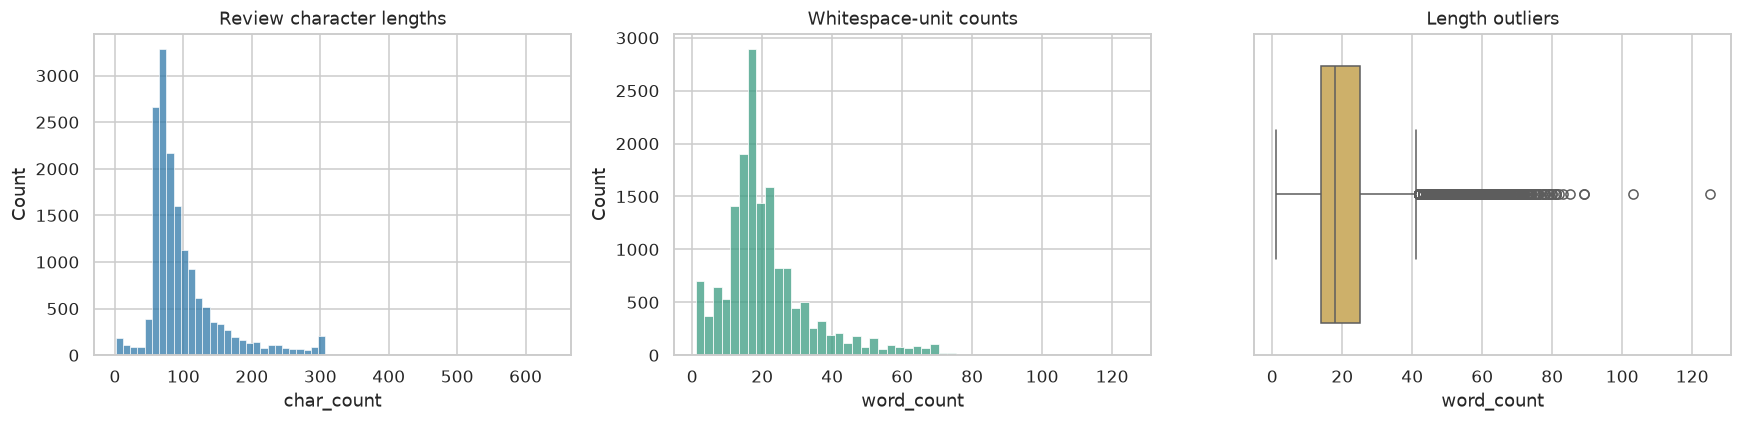

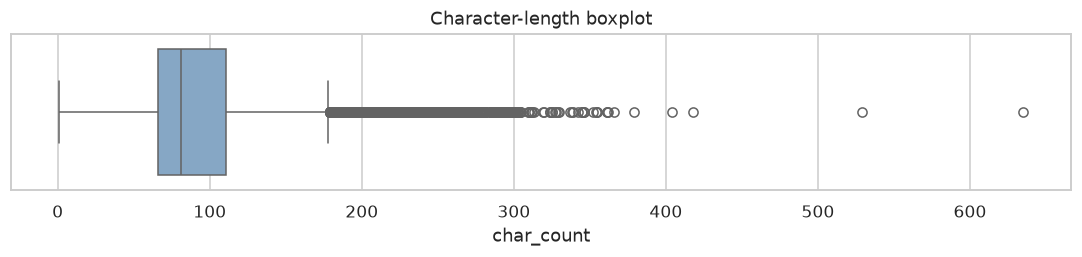

,group,count,percent
0,≤3 whitespace units,701,4.32
1,≥p99 whitespace units,181,1.12


,_row_id,data,word_count,char_count
1763,1763,73(3+7₫(2)1)1?@!-#(#!#:#-+#!#(#((@(1(1((2(((!3;2+;,1,50
2545,2545,Sjhdkdkdjkđnjdjỳùudùkvkvvkvkgìifdydufjfkgkgogogiggigi,1,53
1683,1683,Kdkdkdkdndndmmdmdkdmdmdmkdkdkkdjdndnkdkdkdkkdmdmdndnjd,1,54
1687,1687,🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰,1,50
1715,1715,..................................................,1,50


,_row_id,data,word_count,char_count
7737,7737,"Công dụng: mau dep, nude sieu xinh. Ca nhan minh thay mau 104 dep hon kh chi ve mau ma ca chat son cung dep hon\nKết cấu: son li nhung nhanh troi, quet 1 cai la troi het sach, ...",125,529
1156,1156,"Công dụng: làm đẹp\nKết cấu: dễ sử dụng\nĐộ bền màu: khá lâu trôi nhen , son môi lên màu lắm, dùng lớp dưỡng trc khi son nha ,\nmình từng dùng màu 12 r rất ưng , mà nay đổi qua...",103,418
7765,7765,"Công dụng: son kem chất đẹp và sử dụng mượt\nKết cấu: đẹp và xinh\nĐộ bền màu: 60 % / nói chung là cần kết hợp son khác\nSản phẩm đẹp nha mn, rẻ mà xinh- nói chug là cần kết hợ...",89,366


**Interpretation.** Median review length is 18 whitespace units; mean 21.2. p95 is 50, p99 is 68, and the maximum is 125. The right tail deserves truncation checks, while very short texts may lack enough context to justify their aspect labels.

In [ ]:
def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text)).lower()
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return re.sub(r"[\s_]+", " ", text).strip()

def tokens(text):
    return normalize_text(text).split()

reviews["_normalized"] = reviews[TEXT].map(normalize_text)
reviews["char_count"] = reviews[TEXT].astype(str).str.len()
reviews["word_count"] = reviews[TEXT].astype(str).str.split().str.len()
reviews["sentence_count"] = reviews[TEXT].map(lambda s: len([x for x in re.split(r"[.!?\n]+", str(s)) if x.strip()]))
reviews["unique_token_count"] = reviews[TEXT].map(lambda s: len(set(tokens(s))))
length_summary = reviews[["char_count", "word_count", "sentence_count", "unique_token_count"]].describe(
    percentiles=[.5, .75, .90, .95, .99]).T
display(length_summary.round(2))
all_token_counts = Counter(t for s in reviews[TEXT] for t in tokens(s))
print(f"Corpus normalized token types: {len(all_token_counts):,}; token occurrences: {sum(all_token_counts.values()):,}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=reviews, x="char_count", bins=60, ax=axes[0], color="#3078a8")
sns.histplot(data=reviews, x="word_count", bins=50, ax=axes[1], color="#399b80")
sns.boxplot(data=reviews, x="word_count", ax=axes[2], color="#ddb75a")
for ax, title in zip(axes, ["Review character lengths", "Whitespace-unit counts", "Length outliers"]):
    ax.set_title(title)
plt.tight_layout(); plt.show()
# Separate axes prevent characters and words from being mixed on one scale.
fig, ax = plt.subplots(figsize=(10, 2.5))
sns.boxplot(data=reviews, x="char_count", color="#7ca8cf", ax=ax)
ax.set_title("Character-length boxplot")
plt.tight_layout(); plt.show()

short_mask = reviews["word_count"].le(3)
long_cutoff = reviews["word_count"].quantile(.99)
long_mask = reviews["word_count"].ge(long_cutoff)
display(pd.DataFrame({"group": ["≤3 whitespace units", "≥p99 whitespace units"],
                      "count": [short_mask.sum(), long_mask.sum()],
                      "percent": [short_mask.mean()*100, long_mask.mean()*100]}).round(2))
show_examples(reviews.loc[short_mask].sort_values("word_count"), ["_row_id", TEXT, "word_count", "char_count"])
show_examples(reviews.loc[long_mask].sort_values("word_count", ascending=False), ["_row_id", TEXT, "word_count", "char_count"], n=3)
interpretation(f"Median review length is {reviews.word_count.median():.0f} whitespace units; mean {reviews.word_count.mean():.1f}. "
               f"p95 is {reviews.word_count.quantile(.95):.0f}, p99 is {long_cutoff:.0f}, and the maximum is {reviews.word_count.max():.0f}. "
               "The right tail deserves truncation checks, while very short texts may lack enough context to justify their aspect labels.")

## 4. Text content: words and contiguous n-grams
Normalization preserves Vietnamese accents and operates only on analysis copies. A small transparent stopword list removes common function words for unigram counts. Negation/intensity words such as `không`, `chưa`, `rất`, `quá` are deliberately retained. Bigram/trigram counts preserve **original adjacency** in the normalized text; only all-stopword n-grams are excluded. These are syllable/token sequences, not segmented Vietnamese words. Counts use the full corpus and can be influenced by duplicate reviews.

Analysis-only unigram stopwords: ['bạn', 'cho', 'các', 'có', 'của', 'em', 'là', 'mà', 'mình', 'một', 'nha', 'nhé', 'những', 'này', 'shop', 'thì', 'tôi', 'và', 'với', 'á', 'đó', 'ạ']


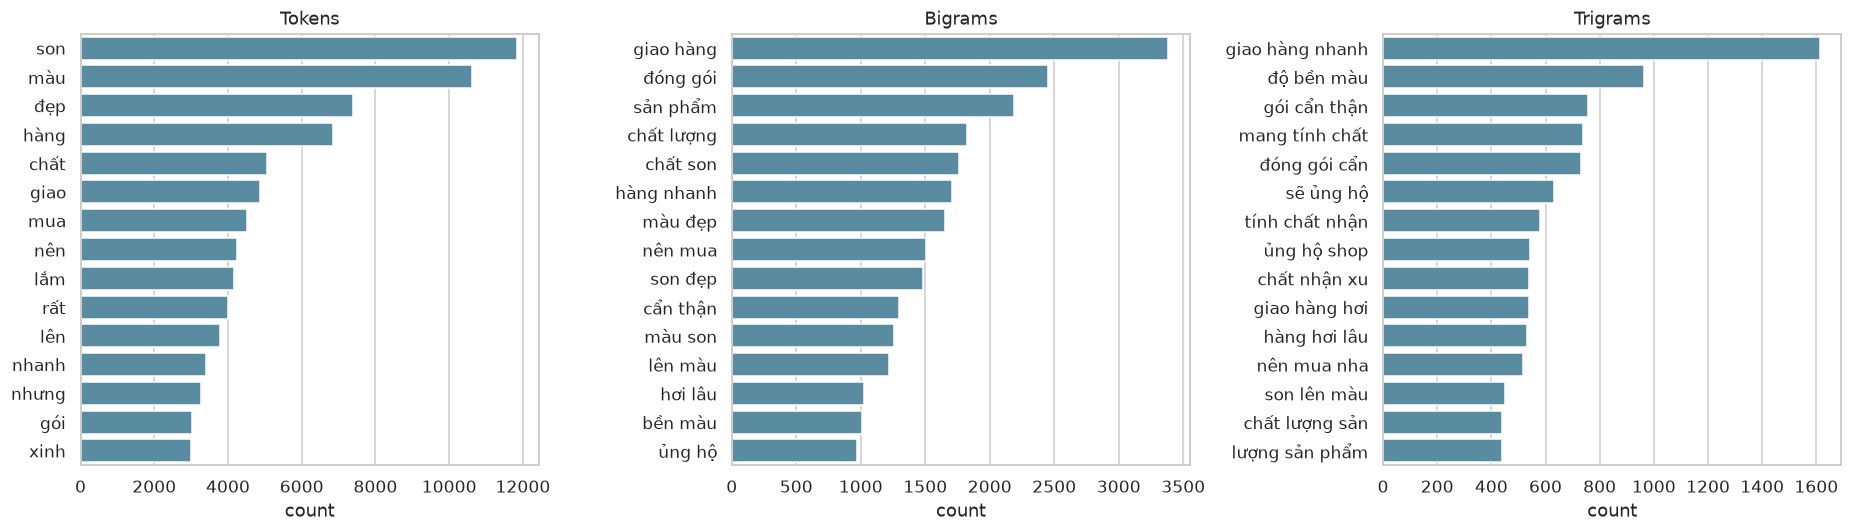

,unigrams,bigrams,trigrams
0,"son (11,840)","giao hàng (3,384)","giao hàng nhanh (1,612)"
1,"màu (10,631)","đóng gói (2,451)",độ bền màu (962)
2,"đẹp (7,397)","sản phẩm (2,187)",gói cẩn thận (756)
3,"hàng (6,842)","chất lượng (1,823)",mang tính chất (739)
4,"chất (5,055)","chất son (1,758)",đóng gói cẩn (730)
5,"giao (4,857)","hàng nhanh (1,705)",sẽ ủng hộ (630)
6,"mua (4,516)","màu đẹp (1,656)",tính chất nhận (581)
7,"nên (4,253)","nên mua (1,503)",ủng hộ shop (544)
8,"lắm (4,154)","son đẹp (1,486)",chất nhận xu (539)
9,"rất (4,001)","cẩn thận (1,298)",giao hàng hơi (538)


**Interpretation.** Frequent terms and phrases reveal product vocabulary and repeated feedback patterns. The leading terms son, màu, đẹp and the phrase giao hàng nhanh support a cosmetics/product-feedback interpretation. Phrases such as mang tính chất also warrant checking for boilerplate or filler reviews. High frequency alone does not imply sentiment: negation and surrounding words matter. These normalized tokens are for inspection, not a proposed BERT input pipeline.

In [ ]:
STOPWORDS = set("và là của có cho với thì mà này đó những các một mình em tôi bạn shop nha nhé ạ á".split())
print("Analysis-only unigram stopwords:", sorted(STOPWORDS))
unigrams = Counter()
bigrams = Counter()
trigrams = Counter()
for text in reviews[TEXT]:
    ts = tokens(text)
    unigrams.update(t for t in ts if t not in STOPWORDS and not t.isdigit())
    for n, counter in [(2, bigrams), (3, trigrams)]:
        counter.update(" ".join(ts[i:i+n]) for i in range(len(ts)-n+1)
                       if any(t not in STOPWORDS for t in ts[i:i+n]))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, counter, title in zip(axes, [unigrams, bigrams, trigrams], ["Tokens", "Bigrams", "Trigrams"]):
    top = pd.DataFrame(counter.most_common(15), columns=["term", "count"])
    sns.barplot(data=top, x="count", y="term", color="#4d91ad", ax=ax)
    ax.set_title(title)
    ax.set_ylabel("")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"unigrams": [f"{x} ({c:,})" for x,c in unigrams.most_common(10)],
                      "bigrams": [f"{x} ({c:,})" for x,c in bigrams.most_common(10)],
                      "trigrams": [f"{x} ({c:,})" for x,c in trigrams.most_common(10)]}))
interpretation("Frequent terms and phrases reveal product vocabulary and repeated feedback patterns. "
               "The leading terms son, màu, đẹp and the phrase giao hàng nhanh support a cosmetics/product-feedback interpretation. "
               "Phrases such as mang tính chất also warrant checking for boilerplate or filler reviews. "
               "High frequency alone does not imply sentiment: negation and surrounding words matter. "
               "These normalized tokens are for inspection, not a proposed BERT input pipeline.")

## 5. Aspect distribution
The wide column names enumerate the aspect inventory. `annotation_percent` sums to 100%; `review_percent` measures the share of review rows mentioning each aspect and can sum above 100% because a review can have multiple aspects. “Rare” is flagged using a configurable support threshold of 100 annotations, plus relative imbalance; this is a diagnostic threshold, not a statistical rule.

,count,annotation_percent,review_percent,under_100
aspect,,,,
colour,7519,22.94,46.34,False
shipping,5469,16.69,33.70,False
texture,4887,14.91,30.12,False
price,3286,10.03,20.25,False
packing,3052,9.31,18.81,False
smell,2911,8.88,17.94,False
others,2872,8.76,17.70,False
stayingpower,2779,8.48,17.13,False


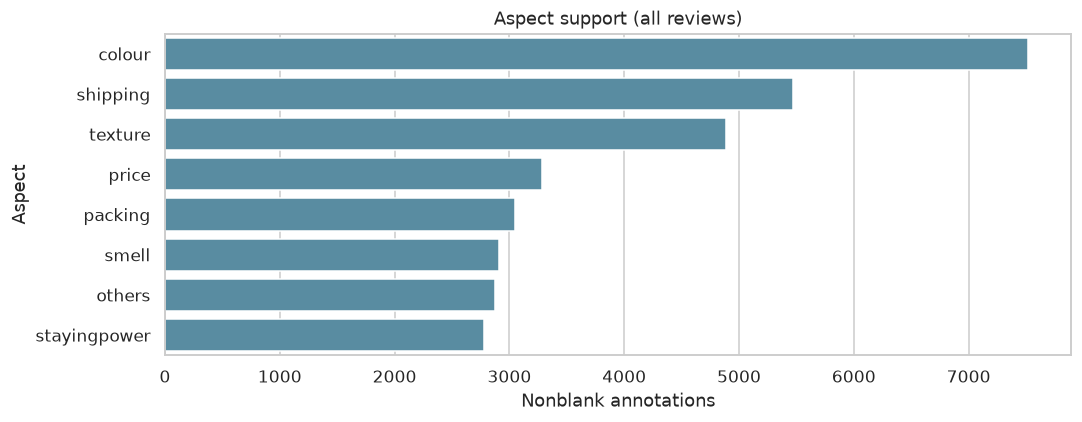

,count,percent
aspect_count,,
0,16,0.10
1,6565,40.46
2,4733,29.17
3,3320,20.46
4,1241,7.65
5,297,1.83
6,50,0.31
7,5,0.03


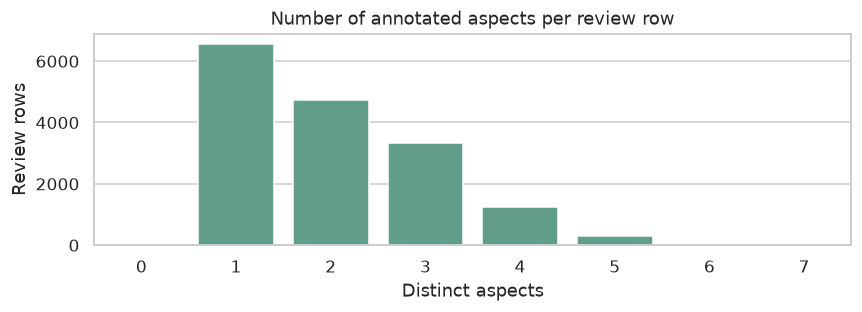

**Interpretation.** The most common aspect is **colour** (22.9% of annotations); the least common is **stayingpower** (2,779 annotations). 59.4% of review rows have multiple aspects. Aspect presence should therefore be treated as multilabel, rather than a single mutually exclusive category.

In [ ]:
RARE_THRESHOLD = 100
aspect_dist = distribution(annotations["aspect"], ASPECTS).rename(columns={"percent": "annotation_percent"})
aspect_dist["review_percent"] = annotations.groupby("aspect")["_row_id"].nunique().reindex(ASPECTS, fill_value=0) / N * 100
aspect_dist["under_100"] = aspect_dist["count"] < RARE_THRESHOLD
aspect_dist = aspect_dist.sort_values("count", ascending=False)
display(aspect_dist.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=aspect_dist["count"], y=aspect_dist.index, color="#4d91ad", ax=ax)
ax.set(xlabel="Nonblank annotations", ylabel="Aspect", title="Aspect support (all reviews)")
plt.tight_layout(); plt.show()
review_labels = annotations.groupby("_row_id").agg(label_count=("sentiment", "size"),
    aspect_count=("aspect", "nunique"), sentiment_diversity=("sentiment", "nunique"))
reviews = reviews.join(review_labels, on="_row_id")
reviews[["label_count", "aspect_count", "sentiment_diversity"]] = reviews[["label_count", "aspect_count", "sentiment_diversity"]].fillna(0).astype(int)
display(distribution(reviews["aspect_count"]).sort_index().round(2))
fig, ax = plt.subplots(figsize=(8, 3))
sns.countplot(data=reviews, x="aspect_count", color="#59a58d", ax=ax)
ax.set(title="Number of annotated aspects per review row", xlabel="Distinct aspects", ylabel="Review rows")
plt.tight_layout(); plt.show()
interpretation(f"The most common aspect is **{aspect_dist.index[0]}** ({aspect_dist.iloc[0]['annotation_percent']:.1f}% of annotations); "
               f"the least common is **{aspect_dist.index[-1]}** ({int(aspect_dist.iloc[-1]['count']):,} annotations). "
               f"{reviews.aspect_count.gt(1).mean()*100:.1f}% of review rows have multiple aspects. "
               "Aspect presence should therefore be treated as multilabel, rather than a single mutually exclusive category.")

## 6. Sentiment distribution
Sentiment counts use **annotations**, because different aspects of a review may have different sentiments. Unannotated cells are excluded, not converted into neutral examples. Unknown nonblank labels, if present, remain visible as extra classes and are flagged in data quality.

,count,percent
sentiment,,
positive,23328,71.18
negative,4652,14.19
neutral,4795,14.63


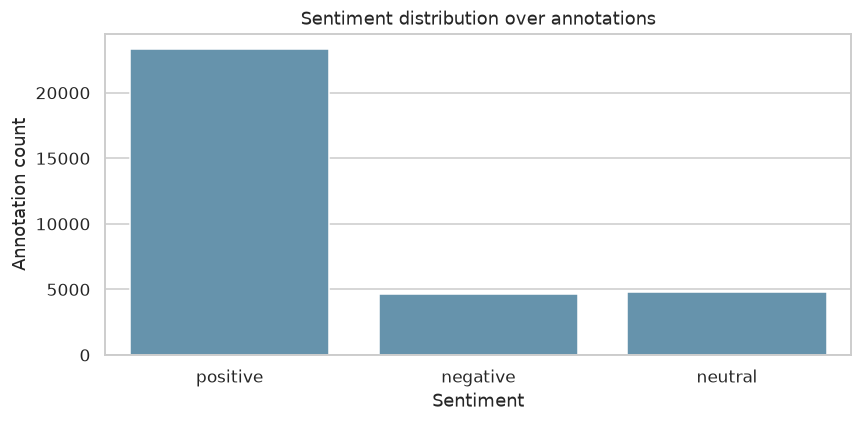

**Interpretation.** **positive** contributes 71.2% of annotations. A model can score well on overall accuracy while missing minority sentiment labels; per-class metrics are necessary.

In [ ]:
sentiment_dist = distribution(annotations["sentiment"], SENTIMENT_ORDER)
display(sentiment_dist.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=sentiment_dist.index, y=sentiment_dist["count"], color="#5a97b8", ax=ax)
ax.set(title="Sentiment distribution over annotations", xlabel="Sentiment", ylabel="Annotation count")
plt.tight_layout(); plt.show()
interpretation(f"**{sentiment_dist['count'].idxmax()}** contributes {sentiment_dist['percent'].max():.1f}% of annotations. "
               "A model can score well on overall accuracy while missing minority sentiment labels; per-class metrics are necessary.")

## 7. Aspect × sentiment: the central ABSA view
Both raw counts and percentages within each aspect are necessary: a high negative percentage for a rare aspect can still mean little training evidence. All expected sentiment columns are shown, including zero cells. A combination below 100 annotations is flagged; later split analysis checks its actual **training** support.

sentiment,positive,negative,neutral
aspect,,,
stayingpower,1521,940,318
texture,3545,796,546
smell,2341,440,130
price,3238,21,27
others,0,0,2872
colour,6315,662,542
shipping,3435,1692,342
packing,2933,101,18


sentiment,positive,negative,neutral
aspect,,,
stayingpower,54.73,33.83,11.44
texture,72.54,16.29,11.17
smell,80.42,15.12,4.47
price,98.54,0.64,0.82
others,0.00,0.00,100.00
colour,83.99,8.80,7.21
shipping,62.81,30.94,6.25
packing,96.10,3.31,0.59


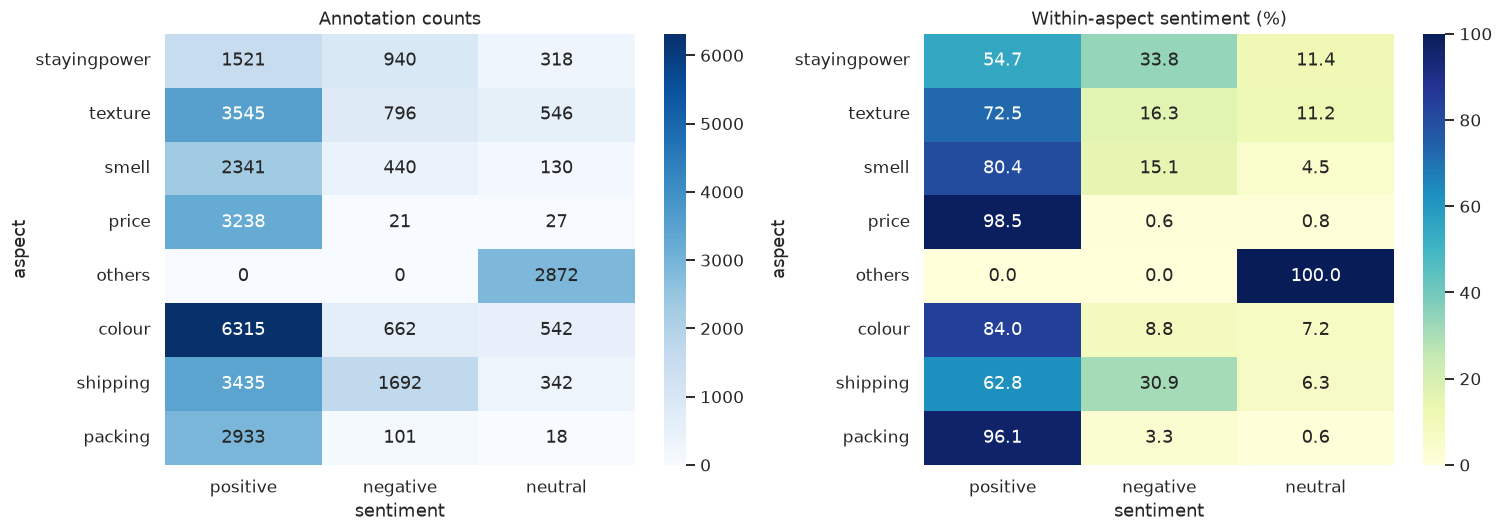

,aspect,sentiment,count,percent_all_annotations
13,others,negative,0,0.000000
12,others,positive,0,0.000000
23,packing,neutral,18,0.054920
10,price,negative,21,0.064073
11,price,neutral,27,0.082380


,dominant_sentiment,dominant_percent,total
aspect,,,
stayingpower,positive,54.73,2779
texture,positive,72.54,4887
smell,positive,80.42,2911
price,positive,98.54,3286
others,neutral,100.00,2872
colour,positive,83.99,7519
shipping,positive,62.81,5469
packing,positive,96.10,3052


**Interpretation.** **stayingpower** has the largest negative share (33.8%). There are 5 aspect–sentiment cells with fewer than 100 annotations. Global sentiment balance hides these aspect-specific differences; inspect support before interpreting any per-aspect score.

**Interpretation.** The `others` aspect is 100% neutral, with zero positive or negative support. This may reflect a catch-all annotation convention, not a naturally balanced sentiment task. Price and packing are overwhelmingly positive. Verify the meaning of others and its allowed labels before modeling; zero observed combinations are not automatically invalid combinations.

In [ ]:
combo_counts = pd.crosstab(annotations["aspect"], annotations["sentiment"]).reindex(index=ASPECTS, columns=SENTIMENT_ORDER, fill_value=0)
combo_pct = combo_counts.div(combo_counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
display(combo_counts)
display(combo_pct.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(combo_counts, annot=True, fmt="d", cmap="Blues", ax=axes[0])
sns.heatmap(combo_pct, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100, ax=axes[1])
axes[0].set_title("Annotation counts"); axes[1].set_title("Within-aspect sentiment (%)")
plt.tight_layout(); plt.show()
combo_support = combo_counts.rename_axis(index="aspect", columns="sentiment").stack().rename("count").reset_index()
combo_support["percent_all_annotations"] = combo_support["count"] / max(A, 1) * 100
rare_combos = combo_support.loc[combo_support["count"] < RARE_THRESHOLD].sort_values("count")
display(rare_combos)
aspect_patterns = pd.DataFrame({"dominant_sentiment": combo_counts.idxmax(axis=1),
                               "dominant_percent": combo_pct.max(axis=1), "total": combo_counts.sum(axis=1)})
display(aspect_patterns.round(2))
negative_leader = combo_pct["negative"].idxmax()
interpretation(f"**{negative_leader}** has the largest negative share ({combo_pct.loc[negative_leader, 'negative']:.1f}%). "
               f"There are {len(rare_combos)} aspect–sentiment cells with fewer than {RARE_THRESHOLD} annotations. "
               "Global sentiment balance hides these aspect-specific differences; inspect support before interpreting any per-aspect score.")
interpretation(f"The `others` aspect is {combo_pct.loc['others', 'neutral']:.0f}% neutral, with zero positive or negative support. "
               "This may reflect a catch-all annotation convention, not a naturally balanced sentiment task. "
               "Price and packing are overwhelmingly positive. Verify the meaning of others and its allowed labels before modeling; "
               "zero observed combinations are not automatically invalid combinations.")

## 8. Review-level annotation structure
A wide-format row can have at most one label per aspect, so label count and aspect count coincide within a row. Sentiment diversity can still exceed one. The second table groups identical text across records to expose repetition; without source IDs, it cannot prove that these records belong to the same original review.

In [ ]:
display(reviews[["label_count", "aspect_count", "sentiment_diversity"]].describe().round(2))
display(distribution(reviews["sentiment_diversity"]).sort_index().round(2))
exact_review_groups = annotations.groupby(TEXT).agg(annotation_occurrences=("sentiment", "size"),
    distinct_aspects=("aspect", "nunique"), distinct_sentiments=("sentiment", "nunique"), record_count=("_row_id", "nunique"))
show_examples(exact_review_groups.sort_values("record_count", ascending=False).reset_index(), n=5)
for title, mask in [("One annotated aspect", reviews.aspect_count.eq(1)),
                    ("Multiple aspects", reviews.aspect_count.gt(1)),
                    ("Mixed sentiments across aspects", reviews.sentiment_diversity.gt(1))]:
    display(Markdown("**" + title + "**"))
    sample = reviews.loc[mask].sample(min(2, int(mask.sum())), random_state=SEED)
    show_examples(sample, ["_row_id", TEXT] + ASPECTS, n=2, full_text=True)
interpretation(f"{reviews.sentiment_diversity.gt(1).sum():,} rows ({reviews.sentiment_diversity.gt(1).mean()*100:.1f}%) "
               "contain multiple sentiment labels. This is expected ABSA behavior when different aspects are judged differently, "
               "and is not itself an annotation conflict.")

,label_count,aspect_count,sentiment_diversity
count,16227.00,16227.00,16227.00
mean,2.02,2.02,1.28
std,1.07,1.07,0.49
min,0.00,0.00,0.00
25%,1.00,1.00,1.00
50%,2.00,2.00,1.00
75%,3.00,3.00,2.00
max,7.00,7.00,3.00


,count,percent
sentiment_diversity,,
0,16,0.10
1,12009,74.01
2,3884,23.94
3,318,1.96


,data,annotation_occurrences,distinct_aspects,distinct_sentiments,record_count
0,NAN,105,1,1,105
1,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cảm ơn người vận chuyể...",31,2,2,31
2,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận chuyển đã nâng như nân...",25,2,1,16
3,Thời gian vận chuyển rất hợp lí. Tôi đã đặt hàng với tâm thế hào hứng chờ đợi để được trải nghiệm sản phẩm và tôi không hề bị chờ mỏi cổ. Có thể thấy bên vận chuyển không quản ...,13,1,1,13
4,Đẹp,5,1,1,5


**One annotated aspect**

,_row_id,data,stayingpower,texture,smell,price,others,colour,shipping,packing
6735,6735,Son ok lắm nhe mọi người vì dịch nên mình nhận được hàng hơi trễ nhưng không sao son đánh lên môi đẹp lắm nhe không có khó táng như mọi người nói 😊😊😊,,,,,,,negative,
14800,14800,Giao hàng hơi lâuuu -.-\nSon đẹp lắm nha mnggg\nLần sau lại ghé shop nhoaaaaaaa,,,,,,,negative,


**Multiple aspects**

,_row_id,data,stayingpower,texture,smell,price,others,colour,shipping,packing
3585,3585,Giáo hàng khá nhanh.. đóng gói chắc chắn . Nhìn chung thì tuỵt dời lắm ạ,,,,,,,positive,positive
5320,5320,"Son lên màu xinh chuẩn, son thơm, giao hàng nhanh giá rẻ phù hợp giá tìn nha.",,,positive,positive,,positive,positive,


**Mixed sentiments across aspects**

,_row_id,data,stayingpower,texture,smell,price,others,colour,shipping,packing
9421,9421,"Son có mùi ngọt, béo.... ngửi mà thèm kẹo ghê luôn. Màu cũng đẹp. Tuy nhiên nhanh trôi",negative,,positive,,,positive,,
9039,9039,"Mới tập thử son nên khong biết chất liệu ra sao nhưng son có mùi socola rất dễ chịu . người ship hàng dethuong , hàng quốc tế nên ship hơi lâu",,,positive,,,,neutral,


**Interpretation.** 4,202 rows (25.9%) contain multiple sentiment labels. This is expected ABSA behavior when different aspects are judged differently, and is not itself an annotation conflict.

## 9. Label consistency and suspicious annotations
Check identical original text with different complete label vectors, identical text–aspect pairs with multiple sentiments, and repeated text–aspect–sentiment triples. Repeated triples across records may be duplicate annotations; the same sentiment assigned to *different* aspects is valid. In this wide schema a single row cannot store two separate sentiments for one aspect; compound strings would instead be invalid labels. No other forbidden aspect–sentiment combinations are documented, so none are invented.

In [ ]:
label_vectors = reviews[ASPECTS].apply(lambda s: s.astype(str).str.strip().str.lower()).apply(tuple, axis=1)
vector_frame = reviews[["_row_id", TEXT]].assign(_label_vector=label_vectors)
vector_counts = vector_frame.groupby(TEXT)["_label_vector"].nunique()
inconsistent_texts = vector_counts[vector_counts.gt(1)].index
conflict_pairs = annotations.groupby([TEXT, "aspect"]).agg(
    sentiment_count=("sentiment", "nunique"),
    sentiments=("sentiment", lambda s: ", ".join(sorted(set(s)))),
    rows=("_row_id", lambda s: tuple(sorted(set(s)))),
    occurrences=("sentiment", "size"))
conflict_pairs = conflict_pairs.loc[conflict_pairs.sentiment_count.gt(1)].reset_index()
annotation_duplicate_mask = annotations.duplicated([TEXT, "aspect", "sentiment"])
conflict_row_ids = {i for ids in conflict_pairs["rows"] for i in ids}
consistency_summary = pd.DataFrame([
    ("Exact texts with different label vectors", len(inconsistent_texts), reviews[TEXT].nunique()),
    ("Conflicting text–aspect pairs", len(conflict_pairs), annotations.groupby([TEXT, "aspect"]).ngroups),
    ("Review rows in conflicting text–aspect pairs", len(conflict_row_ids), N),
    ("Repeated annotation triples beyond first", int(annotation_duplicate_mask.sum()), A),
    ("Invalid aspect/sentiment combinations under provisional schema", int((~annotations.valid_sentiment | ~annotations.aspect.isin(EXPECTED_ASPECTS)).sum()), A)
], columns=["check", "count", "denominator"])
consistency_summary["percent"] = 100*consistency_summary["count"]/consistency_summary["denominator"].replace(0, np.nan)
display(consistency_summary.round(3))
show_examples(conflict_pairs, n=8, full_text=True)
# Show two different label vectors for the same text together, rather than repeated copies of one vector.
inconsistent_examples = vector_frame.loc[vector_frame[TEXT].isin(inconsistent_texts)].drop_duplicates([TEXT, "_label_vector"])
inconsistent_examples = inconsistent_examples.loc[inconsistent_examples[TEXT].isin(list(inconsistent_texts[:2]))]
inconsistent_example_ids = inconsistent_examples.groupby(TEXT, sort=True).head(2)._row_id
show_examples(reviews.loc[reviews._row_id.isin(inconsistent_example_ids)].sort_values(TEXT),
              ["_row_id", "_split", TEXT] + ASPECTS, n=4, full_text=True)
show_examples(annotations.loc[annotations.duplicated([TEXT, "aspect", "sentiment"], keep=False)],
              ["_row_id", "_split", TEXT, "aspect", "sentiment"], n=5)
interpretation(f"{len(conflict_pairs)} identical text–aspect pairs have conflicting sentiments and "
               f"{len(inconsistent_texts)} distinct texts have differing label vectors. "
               "Differences can reflect annotation noise, omitted aspects, or ambiguous repeated short texts; manual review is required before deletion or consolidation.")

,check,count,denominator,percent
0,Exact texts with different label vectors,6,15970,0.038
1,Conflicting text–aspect pairs,0,32486,0.000
2,Review rows in conflicting text–aspect pairs,0,16227,0.000
3,Repeated annotation triples beyond first,289,32775,0.882
4,Invalid aspect/sentiment combinations under provisional schema,0,32775,0.000


No matching examples.

,_row_id,_split,data,stayingpower,texture,smell,price,others,colour,shipping,packing
117,117,train,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,
2398,2398,train,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
1766,1766,train,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận chuyển đã nâng như nâng trứng, hứng như hứng hoa. Xin nghiêng mình cảm ơn vì tất cả.",,,,,,,positive,positive
3312,3312,test,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận chuyển đã nâng như nâng trứng, hứng như hứng hoa. Xin nghiêng mình cảm ơn vì tất cả.",,,,,,,,positive


,_row_id,_split,data,aspect,sentiment
125,125,train,"Giao hàng nhanh, cầm chắc chắn, chưa đánh kb độ bên có lâu không",stayingpower,neutral
126,126,train,"Giao hàng nhanh, cầm chắc chắn, chưa đánh kb độ bên có lâu không",stayingpower,neutral
5214,5214,train,"Sản phẩm rất ok, son lì mịn với thơm nữa... Giao hàng nhanh hơn dự kiến.",stayingpower,positive
5237,5237,train,mua 2 lần bên nhà focallure rùi vì quá iu son lên màu rất đỉnh bám lâu nữa quá là iu lun mng 🥰,stayingpower,positive
5238,5238,train,mua 2 lần bên nhà focallure rùi vì quá iu son lên màu rất đỉnh bám lâu nữa quá là iu lun mng 🥰,stayingpower,positive


**Interpretation.** 0 identical text–aspect pairs have conflicting sentiments and 6 distinct texts have differing label vectors. Differences can reflect annotation noise, omitted aspects, or ambiguous repeated short texts; manual review is required before deletion or consolidation.

## 10. Text length by label
Each annotation inherits its parent review’s length. A review with several aspects appears in several groups, so these observations are **not independent** and sentiment-group totals are annotation-weighted. Summary statistics always use all annotations; only boxplots are capped at 20,000 reproducibly sampled annotations.

word_count               char_count               
               count   mean median      count    mean median
sentiment                                                   
negative        4652  26.18   22.0       4652  115.07   96.0
neutral         4795  20.95   17.0       4795  105.10   82.0
positive       23328  23.46   20.0      23328  104.78   87.0

word_count               char_count               
                  count   mean median      count    mean median
aspect                                                         
colour             7519  23.65   20.0       7519  104.73   86.0
others             2872  15.96   12.0       2872   91.09   66.0
packing            3052  22.59   19.0       3052  102.15   84.0
price              3286  24.93   21.0       3286  109.34   89.0
shipping           5469  22.52   19.0       5469  102.08   85.0
smell              2911  24.65   20.0       2911  109.57   90.0
stayingpower       2779  26.91   23.0       2779  119.54  101.0
texture            4887  25.66   22.0       4887  113.38   96.0

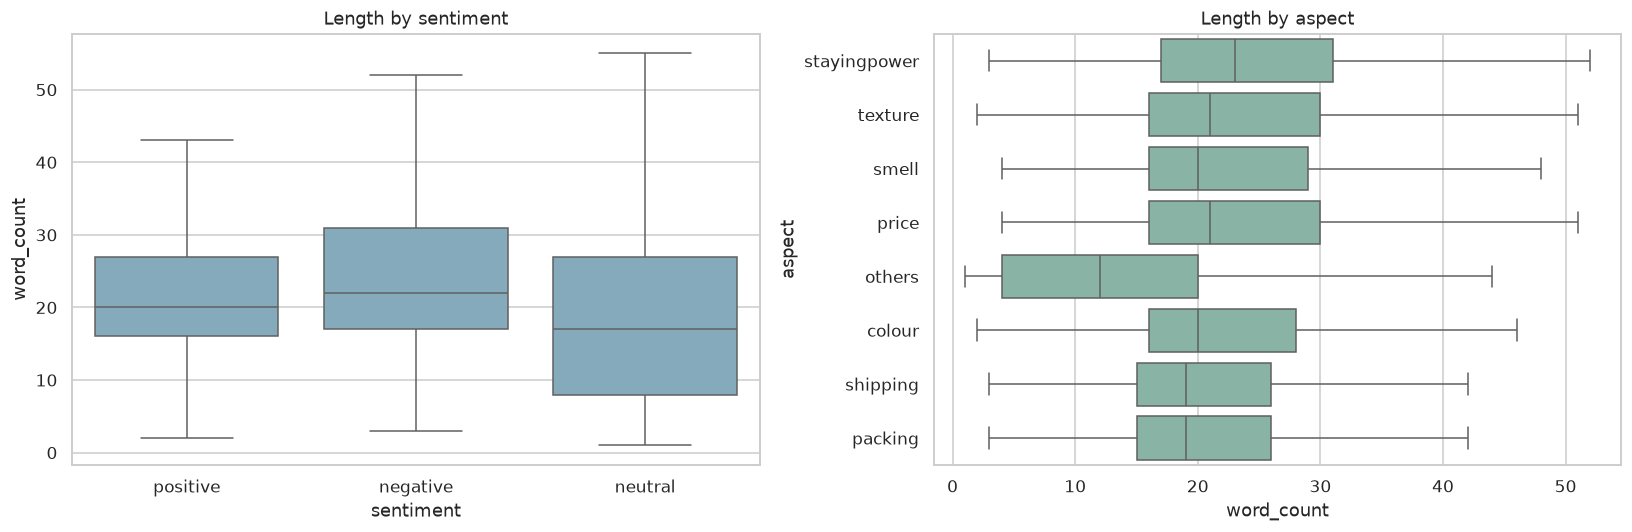

**Interpretation.** Mean lengths by sentiment range from 21.0 to 26.2 whitespace units (neutral to negative); aspect means range from 16.0 to 26.9 (others to stayingpower). These are descriptive associations, potentially confounded by co-occurring aspects and review verbosity. Boxplot outlier markers are hidden for readability, but outliers remain in all statistics.

In [ ]:
annot_lengths = annotations.merge(reviews[["_row_id", "word_count", "char_count"]], on="_row_id", validate="many_to_one")
length_by_sentiment = annot_lengths.groupby("sentiment")[["word_count", "char_count"]].agg(["count", "mean", "median"])
length_by_aspect = annot_lengths.groupby("aspect")[["word_count", "char_count"]].agg(["count", "mean", "median"])
display(length_by_sentiment.round(2))
display(length_by_aspect.round(2))
plot_lengths = annot_lengths.sample(min(20000, len(annot_lengths)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=plot_lengths, x="sentiment", y="word_count", order=SENTIMENT_ORDER, color="#7cadc5", ax=axes[0], showfliers=False)
sns.boxplot(data=plot_lengths, y="aspect", x="word_count", order=ASPECTS, color="#82baa7", ax=axes[1], showfliers=False)
axes[0].set_title("Length by sentiment"); axes[1].set_title("Length by aspect")
plt.tight_layout(); plt.show()
means = annot_lengths.groupby("sentiment")["word_count"].mean()
aspect_means = annot_lengths.groupby("aspect")["word_count"].mean()
interpretation(f"Mean lengths by sentiment range from {means.min():.1f} to {means.max():.1f} whitespace units "
               f"({means.idxmin()} to {means.idxmax()}); aspect means range from {aspect_means.min():.1f} to {aspect_means.max():.1f} "
               f"({aspect_means.idxmin()} to {aspect_means.idxmax()}). "
               "These are descriptive associations, potentially confounded by co-occurring aspects and review verbosity. "
               "Boxplot outlier markers are hidden for readability, but outliers remain in all statistics.")

## 11. Class imbalance assessment
Report the largest/smallest **nonzero** support ratio, zero-support classes, rare classes, majority share, and normalized entropy (1 means uniform). The full aspect × expected sentiment grid is included so absent combinations are visible. These diagnostics do not apply any resampling or class weights.

In [ ]:
def imbalance_stats(counts, name):
    counts = pd.Series(counts, dtype=float)
    nonzero = counts[counts.gt(0)]
    probs = nonzero / max(nonzero.sum(), 1)
    return {"target": name, "classes": len(counts), "zero_support": int(counts.eq(0).sum()),
            "under_100": int(counts.lt(RARE_THRESHOLD).sum()), "min_nonzero": nonzero.min(),
            "max": counts.max(), "max/min_nonzero": nonzero.max()/nonzero.min() if len(nonzero) else np.nan,
            "majority_percent": probs.max()*100 if len(probs) else np.nan,
            "normalized_entropy": -(probs*np.log(probs)).sum()/np.log(len(counts)) if len(counts)>1 else np.nan}
imbalance_table = pd.DataFrame([
    imbalance_stats(sentiment_dist["count"], "sentiment"),
    imbalance_stats(aspect_dist["count"], "aspect"),
    imbalance_stats(combo_support["count"], "aspect × sentiment")])
display(imbalance_table.round(3))
display(combo_support.sort_values("count").head(10).round(3))
interpretation("Overall accuracy and micro-F1 can hide weak performance on rare combinations. "
               "For future experiments, report per-aspect sentiment precision/recall/F1 and support, macro-F1, and joint aspect–sentiment micro/macro-F1. "
               "If predicting aspect presence, also report multilabel presence metrics. Consider train-only class-weighted loss or balanced batches after establishing a baseline; "
               "choose weights and thresholds using training/validation data, not test performance.")

,target,classes,zero_support,under_100,min_nonzero,max,max/min_nonzero,majority_percent,normalized_entropy
0,sentiment,3,0,0,4652.0,23328.0,5.015,71.176,0.728
1,aspect,8,0,0,2779.0,7519.0,2.706,22.941,0.966
2,aspect × sentiment,24,2,5,18.0,6315.0,350.833,19.268,0.802


,aspect,sentiment,count,percent_all_annotations
12,others,positive,0,0.000
13,others,negative,0,0.000
23,packing,neutral,18,0.055
10,price,negative,21,0.064
11,price,neutral,27,0.082
22,packing,negative,101,0.308
8,smell,neutral,130,0.397
2,stayingpower,neutral,318,0.970
20,shipping,neutral,342,1.043
7,smell,negative,440,1.342


**Interpretation.** Overall accuracy and micro-F1 can hide weak performance on rare combinations. For future experiments, report per-aspect sentiment precision/recall/F1 and support, macro-F1, and joint aspect–sentiment micro/macro-F1. If predicting aspect presence, also report multilabel presence metrics. Consider train-only class-weighted loss or balanced batches after establishing a baseline; choose weights and thresholds using training/validation data, not test performance.

## 12. Potential data leakage
Inspect explicit target-like strings inside text, exact and normalized duplicate groups, and available ID/metadata columns. English markers such as `positive` or `shipping: positive` are stronger leakage candidates than normal Vietnamese review headings (`Công dụng`, `Kết cấu`), which may simply come from a review form. These checks are heuristic: absence of a detected marker does not prove absence of leakage. Neither generated row IDs nor filename-derived split names should become model features.

In [ ]:
label_word_pattern = r"\b(?:positive|negative|neutral)\b"
assignment_pattern = r"\b(?:" + "|".join(re.escape(x) for x in ASPECTS) + r")\s*[:=]\s*(?:positive|negative|neutral)\b"
marker_mask = reviews[TEXT].str.contains(label_word_pattern, flags=re.I, regex=True, na=False)
assignment_mask = reviews[TEXT].str.contains(assignment_pattern, flags=re.I, regex=True, na=False)
normal_dup_mask = reviews["_normalized"].duplicated()
display(pd.DataFrame({"check": ["English sentiment marker in text", "Aspect=sentiment pattern", "Normalized duplicate texts beyond first"],
    "count": [marker_mask.sum(), assignment_mask.sum(), normal_dup_mask.sum()],
    "percent_review_rows": [marker_mask.mean()*100, assignment_mask.mean()*100, normal_dup_mask.mean()*100]}).round(3))
show_examples(reviews.loc[marker_mask | assignment_mask], ["_row_id", TEXT] + ASPECTS)

# Association screening is only meaningful for supported, low-cardinality metadata.
metadata_screen = []
for col in metadata_cols:
    joined = annotations[["_row_id", "sentiment"]].merge(reviews[["_row_id", col]], on="_row_id", validate="many_to_one")
    values = reviews[col].astype(str)
    cardinality = values.nunique()
    encodes_label = values.str.contains(label_word_pattern, flags=re.I, regex=True).sum()
    info = {"column": col, "unique_values": cardinality, "values_containing_label": encodes_label,
            "label_marker_pct": 100*encodes_label/N, "weighted_sentiment_purity": np.nan}
    if 1 < cardinality <= 30:
        table = pd.crosstab(joined[col], joined.sentiment)
        supported = table.loc[table.sum(axis=1).ge(20)]
        info["weighted_sentiment_purity"] = supported.max(axis=1).sum()/max(supported.to_numpy().sum(), 1)
    metadata_screen.append(info)
if metadata_screen:
    display(pd.DataFrame(metadata_screen))
else:
    display(Markdown("**No source ID or metadata columns exist**, so ID-encoded labels and metadata–target association cannot be assessed. "
                     "No author, product, timestamp, or collection source is available for grouped/temporal leakage checks."))
interpretation(f"{marker_mask.sum():,} reviews contain explicit English sentiment words; inspect any matches rather than assuming leakage. "
               "The full CSV duplicates the split corpus and must never be appended as extra training data. "
               "Only the review text (and an aspect prompt if required by the chosen architecture) should be model input; aspect-column sentiments are targets.")
interpretation("The single English-marker match uses 'neutral' to describe skin undertone, so manual inspection does not indicate an embedded target label. "
               "The 105 literal NAN texts and punctuation-only texts are also a warning that template/placeholder repetition can affect leakage and content statistics.")

,check,count,percent_review_rows
0,English sentiment marker in text,1,0.006
1,Aspect=sentiment pattern,0,0.000
2,Normalized duplicate texts beyond first,338,2.083


,_row_id,data,stayingpower,texture,smell,price,others,colour,shipping,packing
11460,11460,"shop ship hang kha nhanh, nhieu lan minh mua romand o day roi va lan nao cung ung, gia tot so voi cac cho khac\nmau 25 hop voi da trang- sang co undertone neutral toi cold",,,,positive,,positive,positive,


**No source ID or metadata columns exist**, so ID-encoded labels and metadata–target association cannot be assessed. No author, product, timestamp, or collection source is available for grouped/temporal leakage checks.

**Interpretation.** 1 reviews contain explicit English sentiment words; inspect any matches rather than assuming leakage. The full CSV duplicates the split corpus and must never be appended as extra training data. Only the review text (and an aspect prompt if required by the chosen architecture) should be model input; aspect-column sentiments are targets.

**Interpretation.** The single English-marker match uses 'neutral' to describe skin undertone, so manual inspection does not indicate an embedded target label. The 105 literal NAN texts and punctuation-only texts are also a warning that template/placeholder repetition can affect leakage and content statistics.

## 13. Existing split comparison and overlap checks
Splits are inferred from filenames. Count review rows and annotations separately, compare label proportions and text lengths, and identify exact/normalized text overlap across each split pair. Normalized equality ignores case, punctuation and whitespace; it can merge genuinely distinct reviews and should be reviewed. Exact overlap is computed over the **entire split corpus**, independently of whether it matches the full file.

Normalized empty strings (e.g. punctuation-only reviews) are excluded from normalized overlap to avoid grouping every punctuation-only text together; they are reported in data quality, while their exact-string overlaps remain counted.

,review_rows,unique_texts,mean_words,median_words,p95_words,max_words,row_percent,annotations
_split,,,,,,,,
train,12981,12797,21.18,18.0,50.0,125,80.0,26231
validation,1623,1601,21.04,18.0,48.0,81,10.0,3264
test,1623,1608,21.39,18.0,53.0,85,10.0,3280


**Sentiment counts and percentages within split annotations**

sentiment,positive,negative,neutral
_split,,,
train,18694,3715,3822
validation,2336,466,462
test,2298,471,511


sentiment,positive,negative,neutral
_split,,,
train,71.27,14.16,14.57
validation,71.57,14.28,14.15
test,70.06,14.36,15.58


**Aspect counts and percentages within split annotations**

aspect,stayingpower,texture,smell,price,others,colour,shipping,packing
_split,,,,,,,,
train,2238,3944,2292,2635,2291,6038,4351,2442
validation,264,450,303,323,270,754,584,316
test,277,493,316,328,311,727,534,294


aspect,stayingpower,texture,smell,price,others,colour,shipping,packing
_split,,,,,,,,
train,8.53,15.04,8.74,10.05,8.73,23.02,16.59,9.31
validation,8.09,13.79,9.28,9.90,8.27,23.10,17.89,9.68
test,8.45,15.03,9.63,10.00,9.48,22.16,16.28,8.96


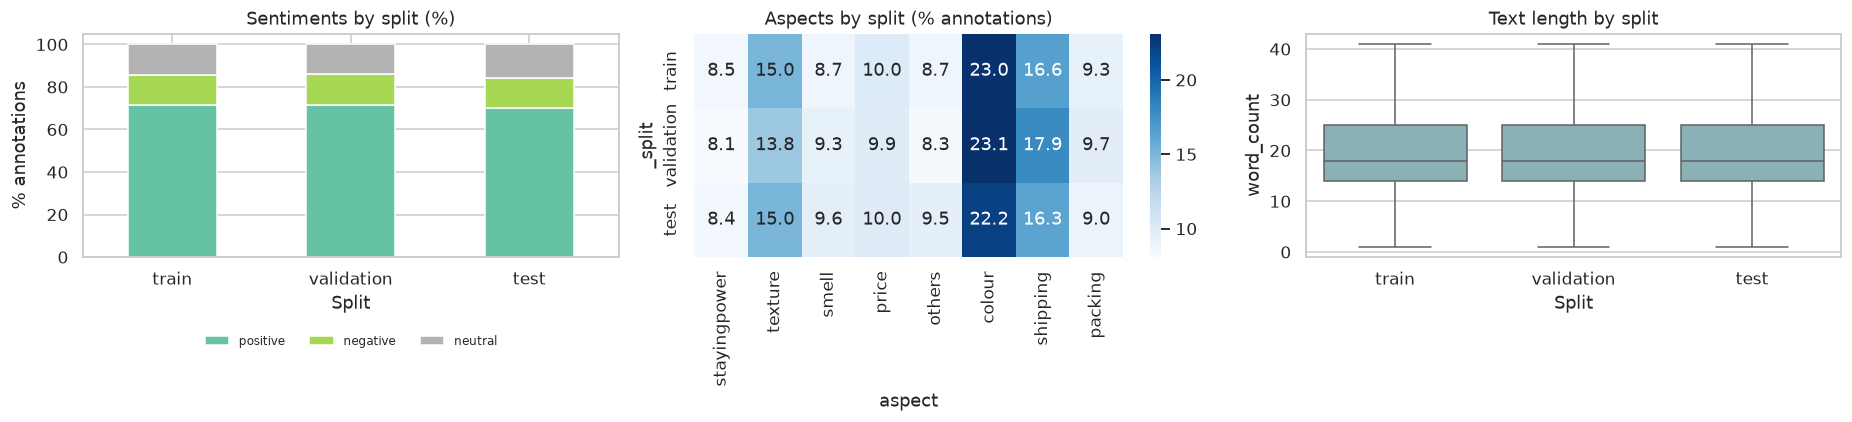

,split_a,split_b,match,shared_unique_texts,rows_a,pct_rows_a,rows_b,pct_rows_b
0,train,validation,exact,18,148,1.140,38,2.341
1,train,validation,normalized,22,179,1.379,48,2.957
2,train,test,exact,18,148,1.140,30,1.848
3,train,test,normalized,21,173,1.333,37,2.280
4,validation,test,exact,5,24,1.479,15,0.924
5,validation,test,normalized,8,33,2.033,21,1.294


,_split_row_id,_split,data,stayingpower,texture,smell,price,others,colour,shipping,packing
10853,10853,train,..................................................,,,,,neutral,,,
964,964,test,..................................................,,,,,neutral,,,
15396,15396,validation,...................................................,,,,,neutral,,,
4483,4483,train,...................................................,,,,,neutral,,,
3616,3616,train,"Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.",,,,,neutral,,,
367,367,test,"Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.",,,,,neutral,,,
3664,3664,train,"Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.",,,,,neutral,,,
9619,9619,train,"Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.",,,,,neutral,,,


Conflicting text–aspect pairs spanning multiple splits: 0


No matching examples.

**Training-only aspect × sentiment support**

sentiment,positive,negative,neutral
aspect,,,
stayingpower,1237,754,247
texture,2880,636,428
smell,1851,340,101
price,2598,15,22
others,0,0,2291
colour,5045,555,438
shipping,2741,1330,280
packing,2342,85,15


**Interpretation.** Similar marginal label/length distributions do not guarantee independent evaluation. 31 exact text strings occur in multiple splits. Group duplicate texts before constructing any revised split; preserve the supplied split files and document any replacement protocol.

In [ ]:
SPLIT_ORDER = [s for s in ["train", "validation", "test"] if not split_raw.empty and s in set(split_raw["_split"])]
split_available = bool(SPLIT_ORDER)
train_combo_counts = None
split_overlap = pd.DataFrame()
if split_available:
    split_reviews = split_raw.copy()
    split_reviews["_split_row_id"] = np.arange(len(split_reviews))
    split_reviews["_normalized"] = split_reviews[TEXT].map(normalize_text)
    split_reviews["word_count"] = split_reviews[TEXT].astype(str).str.split().str.len()
    split_annotations = split_reviews.melt(id_vars=["_split_row_id", "_split", TEXT], value_vars=ASPECTS,
                                           var_name="aspect", value_name="sentiment")
    split_annotations["sentiment"] = split_annotations.sentiment.astype(str).str.strip().str.lower()
    split_annotations = split_annotations.loc[split_annotations.sentiment.ne("")].copy()
    split_summary = split_reviews.groupby("_split").agg(review_rows=(TEXT,"size"), unique_texts=(TEXT,"nunique"),
                  mean_words=("word_count","mean"), median_words=("word_count","median"),
                  p95_words=("word_count",lambda s:s.quantile(.95)), max_words=("word_count","max")).reindex(SPLIT_ORDER)
    split_summary["row_percent"] = split_summary.review_rows/len(split_reviews)*100
    split_summary["annotations"] = split_annotations.groupby("_split").size()
    display(split_summary.round(2))
    split_sentiment = pd.crosstab(split_annotations["_split"], split_annotations.sentiment).reindex(index=SPLIT_ORDER, columns=SENTIMENT_ORDER, fill_value=0)
    split_aspect = pd.crosstab(split_annotations["_split"], split_annotations.aspect).reindex(index=SPLIT_ORDER, columns=ASPECTS, fill_value=0)
    split_sentiment_pct = split_sentiment.div(split_sentiment.sum(axis=1), axis=0)*100
    split_aspect_pct = split_aspect.div(split_aspect.sum(axis=1), axis=0)*100
    display(Markdown("**Sentiment counts and percentages within split annotations**"))
    display(split_sentiment); display(split_sentiment_pct.round(2))
    display(Markdown("**Aspect counts and percentages within split annotations**"))
    display(split_aspect); display(split_aspect_pct.round(2))
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    split_sentiment_pct.plot.bar(stacked=True, ax=axes[0], rot=0, colormap="Set2")
    axes[0].set(title="Sentiments by split (%)", ylabel="% annotations", xlabel="Split")
    axes[0].legend(loc="upper center", bbox_to_anchor=(.5, -.30), ncol=3, fontsize=8, frameon=False)
    sns.heatmap(split_aspect_pct, annot=True, fmt=".1f", cmap="Blues", ax=axes[1])
    axes[1].set_title("Aspects by split (% annotations)")
    sns.boxplot(data=split_reviews, x="_split", y="word_count", order=SPLIT_ORDER, color="#83b6bd", showfliers=False, ax=axes[2])
    axes[2].set(title="Text length by split", xlabel="Split")
    plt.tight_layout(); plt.show()

    overlap_rows = []
    for left, right in combinations(SPLIT_ORDER, 2):
        l = split_reviews.loc[split_reviews._split.eq(left)]
        r = split_reviews.loc[split_reviews._split.eq(right)]
        for key, kind in [(TEXT, "exact"), ("_normalized", "normalized")]:
            shared = (set(l[key]) & set(r[key])) - {""}
            overlap_rows.append({"split_a": left, "split_b": right, "match": kind, "shared_unique_texts": len(shared),
                "rows_a": l[key].isin(shared).sum(), "pct_rows_a": l[key].isin(shared).mean()*100,
                "rows_b": r[key].isin(shared).sum(), "pct_rows_b": r[key].isin(shared).mean()*100})
    split_overlap = pd.DataFrame(overlap_rows)
    display(split_overlap.round(3))
    cross_split_keys = split_reviews.groupby(TEXT)["_split"].nunique()
    cross_split_keys = cross_split_keys[cross_split_keys.gt(1)].index
    show_examples(split_reviews.loc[split_reviews[TEXT].isin(cross_split_keys)].sort_values(TEXT),
                  ["_split_row_id", "_split", TEXT] + ASPECTS, n=8)
    conflict_across_splits = split_annotations.groupby([TEXT, "aspect"]).agg(
        splits=("_split", "nunique"), sentiments=("sentiment", "nunique"))
    conflict_across_splits = conflict_across_splits.loc[conflict_across_splits.splits.gt(1) & conflict_across_splits.sentiments.gt(1)]
    print("Conflicting text–aspect pairs spanning multiple splits:", len(conflict_across_splits))
    show_examples(conflict_across_splits.reset_index(), n=5)
    if "train" in SPLIT_ORDER:
        train_combo_counts = pd.crosstab(split_annotations.loc[split_annotations._split.eq("train"), "aspect"],
                                         split_annotations.loc[split_annotations._split.eq("train"), "sentiment"]).reindex(index=ASPECTS, columns=SENTIMENT_ORDER, fill_value=0)
        display(Markdown("**Training-only aspect × sentiment support**")); display(train_combo_counts)
    interpretation("Similar marginal label/length distributions do not guarantee independent evaluation. "
                   f"{len(cross_split_keys):,} exact text strings occur in multiple splits. "
                   "Group duplicate texts before constructing any revised split; preserve the supplied split files and document any replacement protocol.")
else:
    display(Markdown("**No compatible train/validation/test split files exist.** Split comparison and cross-split leakage checks are unavailable."))

### Approximate near-duplicate screening across splits
This is a bounded **candidate screen**, not an exhaustive semantic similarity audit. It uses up to five rare contiguous word trigrams per unique normalized text, ignores postings with more than 100 texts, keeps at most 30,000 cross-split candidate pairs, requires a length ratio ≥0.8, and flags a character `SequenceMatcher` similarity ≥0.90. Exact normalized matches were already checked above and are excluded here. All split texts participate in indexing; only expensive pair comparisons are bounded. Short texts without three tokens, heavily edited copies, and paraphrases can be missed. Counts below describe reviewed candidates, not corpus prevalence.

Candidate enumeration is deterministic in sorted normalized-text order. If the cap is reached, later texts receive fewer comparisons, so the flagged count is a lower-bound screening result with retrieval-order bias.

In [ ]:
near_pairs = pd.DataFrame(columns=["text_a", "text_b", "splits_a", "splits_b", "similarity"])
near_candidate_count = 0
candidate_cap_hit = False
if split_available:
    unique_texts = split_reviews.loc[split_reviews._normalized.ne("")].groupby("_normalized").agg(
        original=(TEXT, "first"), splits=("_split", lambda s: frozenset(s))).reset_index()
    postings = defaultdict(list)
    shingles = []
    for i, text in enumerate(unique_texts._normalized):
        ts = text.split()
        grams = set(zip(ts, ts[1:], ts[2:]))
        shingles.append(grams)
        for gram in grams:
            postings[gram].append(i)
    candidates = set()
    MAX_CANDIDATES = 30000
    for i, grams in enumerate(shingles):
        selected = sorted((g for g in grams if 1 < len(postings[g]) <= 100), key=lambda g:(len(postings[g]), g))[:5]
        for gram in selected:
            for j in postings[gram]:
                if i == j:
                    continue
                left, right = sorted((i, j))
                a, b = unique_texts.iloc[left], unique_texts.iloc[right]
                if not any(sa != sb for sa in a.splits for sb in b.splits):
                    continue
                if min(len(a._normalized), len(b._normalized))/max(len(a._normalized), len(b._normalized)) < .8:
                    continue
                candidates.add((left, right))
                if len(candidates) >= MAX_CANDIDATES:
                    candidate_cap_hit = True
                    break
            if candidate_cap_hit: break
        if candidate_cap_hit: break
    near_candidate_count = len(candidates)
    matches = []
    for i, j in sorted(candidates):
        a, b = unique_texts.iloc[i], unique_texts.iloc[j]
        ratio = SequenceMatcher(None, a._normalized, b._normalized, autojunk=False).ratio()
        if ratio >= .9:
            matches.append({"text_a": a.original, "text_b": b.original, "splits_a": ", ".join(sorted(a.splits)),
                            "splits_b": ", ".join(sorted(b.splits)), "similarity": ratio})
    if matches:
        near_pairs = pd.DataFrame(matches).sort_values("similarity", ascending=False)
    print(f"Unique normalized texts indexed: {len(unique_texts):,}; pairs compared: {near_candidate_count:,}; cap reached: {candidate_cap_hit}")
    print(f"Flagged pairs: {len(near_pairs):,}; share of compared candidates: {100*len(near_pairs)/max(near_candidate_count,1):.2f}%")
    show_examples(near_pairs, n=5)
    interpretation(f"{len(near_pairs):,} candidate pairs meet the near-duplicate threshold. "
                   "These are potential leakage candidates, not proven duplicate source reviews; inspect both texts. "
                   "Even if no pairs were found, this limited screen would not rule out near-duplicate leakage.")
else:
    print("Near-duplicate split screening skipped: no compatible splits.")

Unique normalized texts indexed: 15,888; pairs compared: 30,000; cap reached: True
Flagged pairs: 66; share of compared candidates: 0.22%


,text_a,text_b,splits_a,splits_b,similarity
32,"Chất lượng sản phẩm tuyệt vời, đóng gói sán phẩm rất đẹp và chắc chắn.","chất lượng sản phẩm tuyệt vời, đóng gói sản phẩm rất đẹp và chắc chắn",train,"test, train, validation",0.985294
8,Chất lượng sản phảm tuyệt vời. Đóng gói sản phẩm rất đẹp và chắc chắn.,"chất lượng sản phẩm tuyệt vời, đóng gói sản phẩm rất đẹp và chắc chắn",test,"test, train, validation",0.985294
21,Chất lượng sản phẩm tuyệt vời giao hàng nhanh đóng gói chắc chắn,"chất lượng sản phẩm tuyệt vời, giao hành nhanh, đóng gói chắc chắn","train, validation",train,0.984375
1,"chat luong san pham tuyet voi,dong goi san pham rat dep va chac chan",Chat luong san phamtuyet voi dong goi san pham rat dep và chac chan,train,test,0.977778
60,"Kết cấu: LÌ\n🥰Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cảm ơn n...","Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cảm ơn người vận chuyể...",train,"test, train, validation",0.975391


**Interpretation.** 66 candidate pairs meet the near-duplicate threshold. These are potential leakage candidates, not proven duplicate source reviews; inspect both texts. Even if no pairs were found, this limited screen would not rule out near-duplicate leakage.

## 14. BERT / transformer preparation analysis
Search the project for a local tokenizer configuration. If `transformers` and a compatible tokenizer are already available, load with `local_files_only=True` and count tokens with special tokens and **without truncation**. No downloads or model weights are required. Otherwise report whitespace-unit coverage only; this is **not actual BERT token coverage**, and Vietnamese subword expansion and model-specific segmentation remain unknown. An aspect prompt also consumes sequence space.

In [ ]:
import importlib.util
local_tokenizer_dirs = sorted({p.parent for p in ROOT.rglob("tokenizer_config.json")
                               if not any(part in {".git", ".venv", "venv", "node_modules"} for part in p.parts)}, key=str)
tokenizer = None
tokenizer_source = None
tokenizer_errors = []
if local_tokenizer_dirs and importlib.util.find_spec("transformers") is not None:
    from transformers import AutoTokenizer
    for path in local_tokenizer_dirs:
        try:
            tokenizer = AutoTokenizer.from_pretrained(str(path), local_files_only=True, trust_remote_code=False)
            tokenizer_source = str(path)
            break
        except Exception as exc:
            tokenizer_errors.append(f"{path}: {type(exc).__name__}: {str(exc)[:120]}")
print("Local tokenizer directories:", [str(p) for p in local_tokenizer_dirs])
if tokenizer_errors: print("Tokenizer load issues:", tokenizer_errors)
if tokenizer is not None:
    token_lengths = []
    for start in range(0, N, 256):
        batch = reviews[TEXT].iloc[start:start+256].astype(str).tolist()
        encoded = tokenizer(batch, add_special_tokens=True, truncation=False, padding=False, verbose=False)
        token_lengths.extend(map(len, encoded["input_ids"]))
    preparation_lengths = pd.Series(token_lengths, index=reviews.index)
    coverage_basis = f"Actual tokenizer tokens including special tokens ({tokenizer_source})"
else:
    preparation_lengths = reviews.word_count
    coverage_basis = "Approximation ONLY: whitespace units, excluding special tokens/aspect prompts"
    display(Markdown("**No usable local tokenizer was found. Coverage below is a word-length proxy, not BERT token coverage.**"))
coverage = pd.DataFrame({"candidate_max_length": [64, 128, 256, 512]})
coverage["covered_count"] = [preparation_lengths.le(limit).sum() for limit in coverage.candidate_max_length]
coverage["covered_percent"] = coverage.covered_count / N * 100
coverage["exceeding_count"] = N - coverage.covered_count
coverage["exceeding_percent"] = 100 - coverage.covered_percent
print("Basis:", coverage_basis)
display(coverage.round(3))
# Split-specific proxy coverage can expose a training/test length mismatch.
if splits_verified:
    display(pd.DataFrame({limit: reviews.assign(_length=preparation_lengths).groupby("_split")["_length"].apply(lambda s: s.le(limit).mean()*100)
                          for limit in [64,128,256,512]}).rename_axis(columns="candidate length").round(2))
interpretation("Use **128 and 256 as candidate sequence lengths for a tokenizer-only follow-up audit**, with 256 a provisional starting point, "
               "not a proven coverage guarantee. Measure the actual chosen tokenizer on training text, including aspect prompts and special tokens, "
               "then choose the smallest length meeting the agreed truncation target (for example 99%). "
               "If a local tokenizer was used above, its measured coverage is stronger evidence; a different tokenizer still needs a fresh audit. "
               "Do not select model settings based on downstream test-set performance.")

Local tokenizer directories: []


**No usable local tokenizer was found. Coverage below is a word-length proxy, not BERT token coverage.**

Basis: Approximation ONLY: whitespace units, excluding special tokens/aspect prompts


,candidate_max_length,covered_count,covered_percent,exceeding_count,exceeding_percent
0,64,15942,98.244,285,1.756
1,128,16227,100.000,0,0.000
2,256,16227,100.000,0,0.000
3,512,16227,100.000,0,0.000


candidate length,64,128,256,512
_split,,,,
test,97.66,100.0,100.0,100.0
train,98.27,100.0,100.0,100.0
validation,98.64,100.0,100.0,100.0


**Interpretation.** Use **128 and 256 as candidate sequence lengths for a tokenizer-only follow-up audit**, with 256 a provisional starting point, not a proven coverage guarantee. Measure the actual chosen tokenizer on training text, including aspect prompts and special tokens, then choose the smallest length meeting the agreed truncation target (for example 99%). If a local tokenizer was used above, its measured coverage is stronger evidence; a different tokenizer still needs a fresh audit. Do not select model settings based on downstream test-set performance.

## 15. Representative examples for manual inspection
Show source text in full for a small fixed number of examples. Common/rare examples are selected reproducibly from observed nonzero combinations; zero-support combinations cannot have examples. Suspicious rows are retained with their locators and labels, not repaired automatically.

In [ ]:
nonzero_combos = combo_support.loc[combo_support["count"].gt(0)].sort_values("count")
for title, subset in [("Common combinations", nonzero_combos.tail(3).sort_values("count", ascending=False)),
                       ("Rare combinations", nonzero_combos.head(3))]:
    display(Markdown("**" + title + "**"))
    picked = []
    for row in subset.itertuples(index=False):
        group = annotations.loc[annotations.aspect.eq(row.aspect) & annotations.sentiment.eq(row.sentiment)]
        picked.append(group.sample(1, random_state=SEED))
    if picked:
        show_examples(pd.concat(picked), ["_row_id", "_split", "aspect", "sentiment", TEXT], n=3, full_text=True)
for title, subset in [("Shortest reviews", reviews.nsmallest(2, "word_count")),
                       ("Longest reviews", reviews.nlargest(2, "word_count")),
                       ("Different aspect sets for identical text", reviews.loc[reviews._row_id.isin(inconsistent_example_ids)].sort_values(TEXT)),
                       ("No annotated aspects", reviews.loc[all_blank]),
                       ("Literal missing-content candidate", reviews.loc[literal_null_text].head(1))]:
    display(Markdown("**" + title + "**"))
    show_examples(subset, ["_row_id", "_split", "word_count", TEXT] + ASPECTS, n=3, full_text=True)
interpretation("Compare rare-label examples with common ones before designing cleaning rules. "
               "Informal spelling, repeated letters, emojis, and missing punctuation can carry sentiment. "
               "Conflicting labels should be adjudicated using source annotation guidance rather than overwritten by majority vote automatically.")

**Common combinations**

,_row_id,_split,aspect,sentiment,data
84058,2923,train,colour,positive,"Màu này đánh hằng ngày nhẹ nhàng ưng lắm luôn í, này mua cho mẹ dùng. Mua đi mua lại mãi dòng này vì ăn uống thoải mái môi vẫn cứ xinh. Mua đi mn👏🏻👏🏻"
26259,10032,train,texture,positive,Sản phẩm dùng rất thích. Phấn đánh rất mịn. Son có dưỡng sài rất mềm môi.
104494,7132,train,shipping,positive,"Màu son đẹp, mùi thơm, giao hàng nhanh, rất đáng tiền nhé"


**Rare combinations**

,_row_id,_split,aspect,sentiment,data
116307,2718,train,packing,neutral,"Giao cũng nhanh, đóng gói tạm được, có thỏi bị bung ra kiểu đã bị mở trước :v hơi móp. Còn đâu ok, màu thì mình chưa test"
48763,82,train,price,negative,Công dụng: sOn mau dejd\r\nKết cấu: NHan dcbahakknxbnxd\r\nĐộ bền màu: rat ben mau nhung nhan duoc hang thi giam gia\r\nNhận đc son thì giảm giá còn 69k tiếc ghê mk mua 159k son
52852,4171,train,price,neutral,Công dụng: để đánh lên môi\r\nKết cấu: đẹp nè\r\nĐộ bền màu: cũng tạm được\r\nMình cảm thấy thích cái cách đóng gói hàng của bên hãng cực .nó kiểu sang mà đẹp ấy .nhưng mà hơi thất vọng là mình mua giá sale mà màu son nó k được giống như trên hãng .sắc nâu nhiều hơn sắc đỏ .k biết là giá sale 129 có đúng không nữa tại mình săn và mua được giá đó á 😢


**Shortest reviews**

...

**No annotated aspects**

,_row_id,_split,word_count,data,stayingpower,texture,smell,price,others,colour,shipping,packing
47,47,test,15,"Đóng gói nhanh, hàng chuẩn đẹp, chưa dùng nên chưa biết chất lượng thế nào",,,,,,,,
67,67,train,16,"Chưa dùng nên ko biết như thế nào nhưng đóng gói, bao bì đẹp, cho 5*",,,,,,,,
117,117,train,15,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,


**Literal missing-content candidate**

,_row_id,_split,word_count,data,stayingpower,texture,smell,price,others,colour,shipping,packing
7562,7562,test,1,NAN,,,,,neutral,,,


**Interpretation.** Compare rare-label examples with common ones before designing cleaning rules. Informal spelling, repeated letters, emojis, and missing punctuation can carry sentiment. Conflicting labels should be adjudicated using source annotation guidance rather than overwritten by majority vote automatically.

## 16. Reproducibility and source integrity
Confirm that source file hashes match their values before analysis. This notebook never writes to the dataset. The final Markdown findings summarize the executed results; if the source data changes, rerun and update those narrative findings as well as inspecting the freshly computed tables.

In [ ]:
source_integrity = pd.DataFrame([{"file": str(p), "sha256": source_hashes[str(p)],
    "unchanged": hashlib.sha256(p.read_bytes()).hexdigest() == source_hashes[str(p)]} for p in paths])
display(source_integrity)
assert source_integrity.unchanged.all(), "A source CSV changed during analysis."
assert len(reviews) == len(raw)
assert annotations._row_id.isin(reviews._row_id).all()
assert int(combo_counts.to_numpy().sum()) == A
print("Source hashes unchanged; review/annotation totals reconcile. No model was trained.")

,file,sha256,unchanged
0,data/data_test.csv,90d1bf0b64105c89346f60d974c5c72c0208c70458c40d5b089ac48486d43d08,True
1,data/data_train.csv,19449cceea317269304464ef7c6c72d5dc70548c6006686d1506e1880bfb9976,True
2,data/data_val.csv,7bbc93fad8db9c78a83f75800119cad65bf65b8f0241c36228d7cbe13d1535b3,True
3,data/full_data.csv,3bda8deecc84d94fff526ad092cadc1dc4a4487e6d1a8c54871e53da95ec780e,True


Source hashes unchanged; review/annotation totals reconcile. No model was trained.


## Key Findings

- **16,227 review rows**, **15,970 distinct exact texts**, **8 aspects**, and **32,775 nonblank aspect–sentiment annotations**. The content is Vietnamese product feedback, largely lipstick/cosmetics; this domain is inferred from examples, not supplied documentation.
- Train/validation/test contain **12,981 / 1,623 / 1,623** reviews (approximately 80/10/10). Together they exactly reproduce `full_data.csv`, including multiplicities; combining all four files would double-count the corpus.
- **59.4%** of rows have multiple aspects; **25.9%** have multiple sentiments across aspects. This is an aspect-level multilabel problem.

## Data Quality Issues

- No empty or whitespace-only review strings and no malformed/noncanonical sentiment labels were found. However, **105 rows (0.647%) contain the literal text `NAN`**, all labeled `others=neutral`: these are possible missing-content placeholders and must not be mistaken for meaningful clean reviews.
- **16 rows (0.099%) have no aspect annotation**; **31 nonempty texts (0.191%) contain no letters or digits**. The latter can include punctuation or emoji and require inspection, not blanket removal.
- **251 fully duplicated rows (1.547%)** and **257 duplicated review texts (1.584%)**, counting occurrences beyond the first. There are **289 repeated annotation triples (0.882% of annotations)**.
- **Six exact text groups have different aspect-label vectors**, but **zero identical text–aspect pairs have conflicting sentiments**. The discrepancies concern annotation presence/absence rather than opposite sentiment labels.
- Blank aspect cells account for 53.7–82.9% of rows depending on aspect. Treating these as “unannotated/absent” is an explicit assumption; absence versus incomplete annotation cannot be resolved without annotation guidelines.

## Label Distribution

- Positive: **23,328 (71.18%)**; neutral: **4,795 (14.63%)**; negative: **4,652 (14.19%)**. Majority/minority sentiment support ratio: **5.02×**.
- `colour` is most common (**7,519; 22.94% of annotations**) and `stayingpower` least common (**2,779; 8.48%**); aspect support ratio is **2.71×**. No aspect has fewer than 100 annotations, but joint-label imbalance is much greater.
- `price` is **98.54% positive**, `packing` **96.10% positive**; `stayingpower` has the largest negative share (**33.83%**), followed by `shipping` (**30.94%**).
- `others` is **100% neutral (2,872 annotations)** and contributes **59.9% of all neutral annotations**. This may encode an annotation convention/catch-all class; confirm its intended meaning.
- Sparse observed combinations include **packing–neutral (18)**, **price–negative (21)**, and **price–neutral (27)**. Training-only counts are **15, 15, and 22**, respectively. `others–positive` and `others–negative` have zero support. Among nonzero joint classes, largest/smallest support is **350.83×**.

## Text Characteristics

- Typical review: **18 whitespace units / 81 characters at the median**; mean **21.19 whitespace units**. These units are often Vietnamese syllables, not segmented words or model tokens.
- Whitespace-length p75/p90/p95/p99: **25 / 38 / 50 / 68**, with range **1–125**. There are **701 rows (4.32%)** with ≤3 units and **181 rows (1.12%)** at or above p99. Literal placeholders remain included in these descriptive statistics.
- Vocabulary analysis preserves Vietnamese characters. Product terms and shipping/packing phrases dominate; visible examples also include gibberish, template text, repeated letters, and punctuation-only content.
- Negative annotations are attached to longer reviews on average (**26.2 units**) than neutral annotations (**21.0**). This is descriptive and may reflect co-occurring aspects, not an intrinsic label property.

## Potential Risks

- **Cross-split duplicates:** 31 exact text strings span multiple splits. Train shares 18 unique exact texts with validation (**38 validation rows; 2.34%**) and 18 with test (**30 test rows; 1.85%**). Overlap can inflate evaluation; these sets are not additive because some texts span all three splits.
- Normalized overlap flags **48 validation rows (2.96%)** and **37 test rows (2.28%)** also present in training. This check excludes strings that become empty after normalization, so it is not simply a superset of exact matching.
- The bounded near-duplicate screen flags **66 candidate pairs** at similarity ≥0.90 among **30,000 comparisons**. The cap was reached; this is an incomplete, retrieval-order-biased screen, not a prevalence estimate or proof of shared source identity.
- No explicit aspect=sentiment text leakage was detected. The one `neutral` text match refers to skin undertone. Source author/product/time IDs and metadata are absent, so author/product/temporal separation cannot be checked.
- Missing-content placeholders, inconsistent annotation presence, repeated samples, extreme joint-class imbalance, and zero-support combinations all require attention. Short repeated phrases alone do not prove duplicate original reviews.

## Recommended Preprocessing

- Preserve the source files and raw text; create a versioned derived dataset with provenance and a documented annotation schema.
- Adjudicate the 16 unannotated rows, 105 `NAN` texts, six inconsistent text groups, and nonlinguistic/boilerplate examples. Confirm the role of `others`, blank cells, and allowed sentiment labels before changing any target.
- Establish a duplicate policy and group confirmed duplicate/near-duplicate records before creating a revised split. Preserve the original benchmark split and disclose any cleaned comparison; do not silently drop evaluation rows.
- Consider Unicode NFC normalization and whitespace cleanup in a derived copy, validating that these preserve meaning. Retain accents, negation, emojis, case and punctuation as appropriate for the selected tokenizer. Do **not** reuse frequency-analysis stopword removal as the transformer preprocessing pipeline.
- Define whether the task is aspect detection, sentiment given an aspect, or joint ABSA, and keep unannotated aspects distinct from neutral sentiment. No destructive cleaning, resampling, or training has been performed here.

## Recommendations for BERT-based ABSA

- No project-local tokenizer is available. **64 / 128 / 256 / 512 whitespace-unit limits cover 98.244% / 100% / 100% / 100%** of rows; these percentages are **not BERT token coverage** and exclude special tokens and aspect prompts.
- Audit **128 and 256** with the actual tokenizer; **256 is a provisional starting point**, not a demonstrated requirement or coverage guarantee. Count prompt/special tokens and choose a length against a stated training-corpus truncation target. Apply any model-required Vietnamese segmentation consistently.
- Establish a baseline, then consider train-derived class weights or balanced batches. Select settings with validation data. Oversampling does not create evidence for zero-support classes and can amplify duplicated/noisy rows.
- Report per-class precision/recall/F1 and support, sentiment macro-F1, and joint aspect–sentiment micro/macro-F1. For aspect detection, add multilabel metrics. Define how unsupported classes enter macro averages and report uncertainty for rare classes.
- Pay particular attention to rare price/packing sentiments, `others` semantics, and negative `stayingpower`/`shipping` examples. Use a documented overlap-controlled evaluation before claiming generalization improvements.
